[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QFL_CircuitBackdoor_Mathur2026.ipynb)

# Quantum federated learning under circuit-level backdoors (CULT): Mathur et al. 2026, step by step

**Paper.** Aakar Mathur, Mohammed Ruknuddin, Ashish Gupta, *Can Quantum Federated Learning Withstand Circuit-Level Backdoors?*, Proceedings of the 35th International Joint Conference on Artificial Intelligence (IJCAI-26), 2026, pp. 4651-4659. DOI: [10.24963/ijcai.2026/518](https://doi.org/10.24963/ijcai.2026/518).

**Authors' public code (reused here).** <https://github.com/AakarM1/CULT-CircUit-Level-backdoor-Threat>, pinned at commit `30570586cfe2cc0984434da6cb1ec6a9483d86c5` (merge of 2026-05-10). The notebook clones that exact commit and imports the authors' own PennyLane circuits (`tasks/mnist.py`, `tasks/cifar.py`), honest and malicious clients (`clients.py`, `clients_attackers.py`), federated server and the five robust aggregators (`server.py`, `utils/flguardian_defense.py`). Nothing of the authors' federated logic is re-implemented.

**What this notebook does**

1. Downloads MNIST and CIFAR-10 (Hugging Face mirror first, torchvision as fallback), explores them and shows how the Dirichlet(0.9) split makes the clients non-IID.
2. Draws the *clean* 4+1 qubit circuit and the four *backdoored* circuits (Grover, Pauli-noise, Bit-flip, Sign-flip) of the authors with `qml.draw_mpl`, and prints qubits, depth and trainable parameters. The CIFAR-10 9-wire circuits are drawn too.
3. Trains the hybrid QNN in a 20-client federation with 0..50 % malicious clients under FedAvg and under Krum, Multi-Krum, FoolsGold, MUD-HoG and FLGuardian, logs update norms of honest and malicious clients (the *stealth* claim), and trains a classical federated baseline on the same data.
4. Prints the paper's numbers next to ours with a verdict per claim, then discusses what can and cannot be concluded.

**How to run.** Colab: *Runtime -> Change runtime type -> CPU*, then *Runtime -> Run all*. `FAST_MODE = True` (default, in the configuration cell) finishes in roughly 10 minutes; `FAST_MODE = False` runs the larger grid (about 1.5 hours on a recent CPU; results of every federated run are cached in `DATA_DIR`, so an interrupted run resumes). No GPU, no IBM account and no Hugging Face token is needed (both datasets are public and ungated).

**What you get at the end.** Class/feature plots of the real data, circuit drawings, accuracy-versus-round curves, a Table-1 style accuracy table (our scaled-down numbers beside the paper's), a defence heatmap, a norm-stealth plot, and a verdict table. Please read the *scale* warning below: absolute accuracies are far below the paper's because a 20-client x 100-round x 5-seed study of this model needs days of CPU time.

## The paper in one page

**Problem.** In quantum federated learning (QFL) a server averages the updates of hybrid quantum-classical models trained by clients. A malicious client can cheat in the *quantum layer*: during local training it swaps the clean variational circuit for a poisoned one.

**Threat model (CULT).** Each malicious client has two attack surfaces.
* **S1, in-training.** With probability rho (the round-level poisoning switch, rho = 0.9) the client replaces `quantum_layer` by an attack circuit for the whole round and multiplies its loss by lambda > 1 (the authors' code uses 2). Four attack circuits: **Grover** phase-oracle (a marked bit-string flags an ancilla; a diffusion step plus the ansatz run only under that flag), **Pauli** rotation (RX, RY, RZ with trigger angles on the flagged branch), **Bit-flip** (truncated QFT plus a CNOT on the flagged branch), **Sign-flip** (a 2-qubit QFT/phase-estimation stub plus RZ and CZ on the flagged branch).
* **S2, post-training.** The raw update is re-shaped to look benign: blend with the nearest history vector, remove the top principal direction of the benign-looking history, rescale to a norm drawn from the history's norm statistics, add camouflage noise and sparsify (paper Eq. 8-9).

**Federated setting.** MNIST and CIFAR-10, K = 20 clients, full participation, T = 100 rounds, E = 1 local epoch of AdamW (lr 1e-3), Dirichlet alpha = 0.9 non-IID split, 5 seeds averaged. Hybrid QNN: a CNN front-end, 4 data qubits + 1 ancilla for MNIST (entangling depth 6; 8 + 1 for CIFAR-10), Pauli-Z read-out, a classical head. PyTorch + PennyLane, classical simulation.

**Defences compared.** FedAvg (no defence), Krum, Multi-Krum, FoolsGold, MUD-HoG, FLGuardian.

**Claims checked here** (numbers from Table 1, Sections 6.4-6.7 and the abstract): clean MNIST accuracy 92.65 %; one attacker (q = 5 %) drops MNIST accuracy to 40.95 / 55.59 / 49.20 / 72.51 % (Grover / Pauli / Bit-flip / Sign-flip), mean 54.56 %; accuracy is *not* monotone in q; robust aggregators cost clean accuracy (Krum only 48.13 % on MNIST, MUD-HoG 91.79 %) and still leave drops of up to about 50 points; malicious updates keep benign-like norms (stealth).

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Clients K, rounds T | 20, 100 | 20 clients; **12 rounds (FAST) / 25 rounds (full)** instead of 100 (CPU budget) |
| Seeds | 5, averaged | 1 seed for most cells, 2 seeds for the headline q = 5 % row in the full run (`# CHOICE`) |
| Training data | all of MNIST (60,000) / CIFAR-10 | **random subsets**: 1,500 (FAST) / 3,000 (full) MNIST training images; 500 / 1,000 test images (`# CHOICE`) |
| Optimiser | AdamW, lr 1e-3, E = 1 | AdamW, **lr 0.003**, E = 1; three times the paper's 1e-3 because the budget is 4x shorter (`# CHOICE`) |
| Batch size | not stated | 32; the last partial batch is kept so no client is idle (`# CHOICE`) |
| Quantum layer | PennyLane `default.qubit`, MNIST 4+1 qubits, depth 6 | the authors' PennyLane QNodes are drawn and checked; **training uses an exact PyTorch re-implementation** (`FastQLayer`) that is asserted equal to the PennyLane QNodes (outputs and gradients, error < 1e-5) because PennyLane costs about 0.1-0.25 s per step (`# CHOICE`) |
| Attack circuits, triggers | Eq. 4-7, trigger values not listed | the authors' code: marked state [1,0,1,0], trigger angles [0.2,1.3,2.0,0.5], period 3, phase 0.25 |
| Poison ratio, loss scale | rho = 0.9, lambda > 1 | rho = 0.9, lambda = 2 (authors' code) |
| Which clients are malicious | persistent set, selection not stated | seeded random choice among clients that own data; nested across q (`# CHOICE`) |
| Malicious fractions q | 5, 10, 20, 30, 40, 50 % | FAST: 20 %; full: 5, 20, 50 % |
| Defence runs | q = 0..50 % | one malicious fraction, q = 20 %, plus a clean (q = 0) run per aggregator |
| FLGuardian | trust-score screening | the authors' class; if it ever filters out *all* clients we keep all of them instead of crashing (`# CHOICE`) |
| CIFAR-10 | 8+1 qubits, full study | **only a smoke test** with the authors' unchanged CIFAR QNet (tiny federation, a few rounds): accuracy there is at chance and proves nothing |

**Scale warning.** Because of the cuts above the clean MNIST accuracy of this notebook is expected to stay far below 92.65 %. Absolute numbers will therefore be "not reached"; what can be tested is *direction and ordering* (does a single malicious client hurt? do robust aggregators cost clean accuracy? are malicious update norms benign-like?).

In [1]:
# Installs (pinned to the versions this notebook was tested with).
# Colab already ships numpy, pandas, scikit-learn, scipy, matplotlib, torch and torchvision.
# Tested locally with: pennylane 0.45.1, torch 2.14.1+cpu, torchvision 0.29.1+cpu, scikit-learn 1.9.1.
# No session restart is normally needed.
import sys, importlib, subprocess

IN_COLAB = "google.colab" in sys.modules

def _have(mod):
    try:
        importlib.import_module(mod)
        return True
    except Exception:
        return False

def _pip(*args):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", *args], check=True)

if IN_COLAB or not _have("pennylane"):
    _pip("pennylane==0.45.1", "huggingface_hub", "pyarrow")
if not (_have("torch") and _have("torchvision")):
    _pip("torch", "torchvision", "--index-url", "https://download.pytorch.org/whl/cpu")
if not _have("huggingface_hub"):
    _pip("huggingface_hub", "pyarrow")
print("environment ready; running in Colab:", IN_COLAB)

environment ready; running in Colab: False


In [2]:
# ===================== CONFIGURATION (every tunable constant lives here) =====================
import os, sys, json, time, random, math, subprocess, warnings, logging
from pathlib import Path

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")     # keep the notebook output small
FAST_MODE = False            # True: ~10 min class demo.  False: larger grid (~1.5 h on a recent CPU)
SEED = 42                   # global seed (data subsets use SEED + run seed)
IBM_TOKEN = ""              # unused: this paper has no hardware experiment (kept for the repo convention)

# Gated data is not needed here (MNIST and CIFAR-10 are public).  If a mirror is ever gated, put your own token
# in Colab Secrets (key HF_TOKEN) or in the HF_TOKEN environment variable; it is resolved only like this:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

IN_COLAB = "google.colab" in sys.modules
DATA_DIR = Path("/content/qfl_cult") if IN_COLAB else Path(os.environ.get("QFL_DATA_DIR", "qfl_cult_data"))
DATA_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = DATA_DIR.resolve()
(DATA_DIR / "results").mkdir(exist_ok=True)

# Authors' public code, pinned.
REPO_URL = "https://github.com/AakarM1/CULT-CircUit-Level-backdoor-Threat.git"
REPO_COMMIT = "30570586cfe2cc0984434da6cb1ec6a9483d86c5"
REPO_DIR = DATA_DIR / "repos" / "cult"

# ---- federated setting taken from the paper (Sec. 6.1, 6.3) ----
K_CLIENTS = 20              # clients, full participation
ALPHA = 0.9                 # Dirichlet concentration of the non-IID split
RHO = 0.9                   # poisoning ratio (round-level poisoning switch)
LOCAL_EPOCHS = 1            # E
N_QUBITS, Q_DEPTH = 4, 6    # MNIST: 4 data qubits (+1 ancilla), entangling depth 6

# ---- budget (CHOICE: scaled down; the paper uses T=100, all 60,000 images, lr 1e-3, 5 seeds) ----
BSZ = 32                    # CHOICE: batch size not given in the paper
LR = 0.003                  # CHOICE: AdamW learning rate (paper 1e-3); 3x larger to move in a 25-round budget
if FAST_MODE:
    N_TRAIN, N_TEST, ROUNDS = 1500, 500, 12
    SEEDS = [1]
    Q_GRID = [0.20]                                  # malicious fractions for the FedAvg table
    EXTRA_SEED_Q = []                                # q values repeated with extra seeds
    EXTRA_SEEDS = []
    DEFENSES = ["mkrum", "mudhog"]
    DEF_ATTACKS = ["grover", "bitflip"]
    CIFAR_ROUNDS, CIFAR_K, CIFAR_N = 1, 4, 96
else:
    N_TRAIN, N_TEST, ROUNDS = 3000, 1000, 25
    SEEDS = [1]
    Q_GRID = [0.05, 0.20, 0.50]
    EXTRA_SEED_Q = [0.05]
    EXTRA_SEEDS = [2]
    DEFENSES = ["mkrum", "mudhog", "krum", "foolsgold", "flguardian"]
    DEF_ATTACKS = ["grover", "noise", "bitflip", "signflip"]
    CIFAR_ROUNDS, CIFAR_K, CIFAR_N = 3, 6, 192
ATTACKS = ["grover", "noise", "bitflip", "signflip"]   # 'noise' is the paper's "Pauli" attack
DEF_Q = 0.20                                            # malicious fraction in the defence study
PAPER_NAME = {"grover": "Grover", "noise": "Pauli", "bitflip": "Bit-flip", "signflip": "Sign-flip"}

print(f"FAST_MODE={FAST_MODE}  N_TRAIN={N_TRAIN} N_TEST={N_TEST} ROUNDS={ROUNDS} K={K_CLIENTS} LR={LR} BSZ={BSZ}")
print("DATA_DIR =", DATA_DIR.resolve())

FAST_MODE=False  N_TRAIN=3000 N_TEST=1000 ROUNDS=25 K=20 LR=0.003 BSZ=32
DATA_DIR = C:\Users\madji\AppData\Local\Temp\claude\C--Users-madji-Desktop-QML\45437630-f2c2-4728-9da2-ce4bbdd7c4ba\scratchpad\run_QC-057_full\qfl_cult_data


In [3]:
# Clone the authors' repository at the pinned commit and import everything.
def ensure_repo():
    if (REPO_DIR / "server.py").exists():
        return
    REPO_DIR.mkdir(parents=True, exist_ok=True)
    run = lambda *a: subprocess.run(["git", *a], cwd=REPO_DIR, check=True, capture_output=True, text=True)
    run("init", "-q")
    run("fetch", "-q", "--depth", "1", REPO_URL, REPO_COMMIT)
    run("checkout", "-q", "FETCH_HEAD")

ensure_repo()
head = subprocess.run(["git", "rev-parse", "HEAD"], cwd=REPO_DIR, capture_output=True, text=True).stdout.strip()
assert head == REPO_COMMIT, f"unexpected commit {head}"
print("authors' repo at commit", head)

import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import transforms
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
import pennylane as qml

warnings.filterwarnings("ignore")
torch.set_num_threads(1)            # tiny tensors: one thread per process is fastest (and leaves the CPU free)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
rng_global = np.random.default_rng(SEED)

sys.path.insert(0, str(REPO_DIR))
os.chdir(DATA_DIR)                  # the repo writes small log files relative to the working directory
from tasks import mnist as R_mnist           # authors' MNIST QNet + the four trojan QNodes
from tasks import cifar as R_cifar           # authors' CIFAR-10 QNet (8 data + 1 ancilla qubits)
import dataloader as R_dataloader            # authors' Dirichlet partitioner
from server import Server                    # authors' server and aggregators
from clients import Client                   # authors' honest client
from clients_attackers import Attacker_QuantumTrojan   # authors' malicious client (S1 + S2)
from utils import utils as R_utils
from utils.flguardian_defense import FLGuardianDefense
logging.disable(logging.CRITICAL)            # the repo logs every client at INFO level

print("python", sys.version.split()[0], "| numpy", np.__version__, "| torch", torch.__version__,
      "| torchvision", torchvision.__version__, "| pennylane", qml.__version__, "| sklearn", sklearn.__version__)

authors' repo at commit 30570586cfe2cc0984434da6cb1ec6a9483d86c5


python 3.12.10 | numpy 2.5.4 | torch 2.14.1+cpu | torchvision 0.29.1+cpu | pennylane 0.45.1 | sklearn 1.9.1


## Dataset Exploration and Visualisation

The paper uses **MNIST** (60,000 training / 10,000 test handwritten digits) and **CIFAR-10** (50,000 / 10,000 colour photos in 10 classes). Both are public. The cells below

1. download them (Hugging Face parquet mirrors `ylecun/mnist` and `uoft-cs/cifar10`; torchvision's own downloader is the fallback),
2. print shapes, feature description and the original label values with their counts,
3. plot the real class distribution and sample images,
4. draw 2-D scatter plots of **real observations coloured by their true class**: first the raw PCA coordinates (PCA fitted on the training split only), then the same coordinates scaled to [0, pi] the way angles would be fed to rotation gates (scaler fitted on the training split, test points clipped),
5. show how the Dirichlet(alpha = 0.9) split turns the training set into 20 non-IID client datasets.

Only random *subsets* of the training/test sets are used for the federated runs (see the configuration cell), but the class counts below are for the complete original splits. In the models, the angles fed to the qubits are **learned** by the CNN front-end, not computed by PCA; the PCA-to-angle plots show how separable the classes are in the same 4 (MNIST) or 8 (CIFAR-10) dimensions that the circuit receives. A scatter of the angles actually learned by the trained federated model is drawn later.

In [4]:
import io
from PIL import Image

CIFAR_CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
MNIST_CLASSES = [str(d) for d in range(10)]

class RawSplit:
    """Lazy split: all labels are available at once, images are decoded only for requested indices."""
    def __init__(self, labels, getter):
        self.labels = np.asarray(labels)
        self._get = getter
    def __len__(self):
        return len(self.labels)
    def get(self, idx):
        return self._get(np.asarray(idx))

def _decode(images, idx):
    return np.stack([np.array(Image.open(io.BytesIO(images[int(i)]["bytes"]))) for i in idx])

_HF = {"mnist": ("ylecun/mnist", "mnist/{s}-00000-of-00001.parquet", "image"),
       "cifar": ("uoft-cs/cifar10", "plain_text/{s}-00000-of-00001.parquet", "img")}

def load_raw(name):
    """Return ({'train': RawSplit, 'test': RawSplit}, source string)."""
    out = {}
    try:
        if os.environ.get("QFL_FORCE_TORCHVISION"):
            raise RuntimeError("forced torchvision fallback")
        from huggingface_hub import hf_hub_download
        repo, pattern, col = _HF[name]
        for s in ("train", "test"):
            path = hf_hub_download(repo, pattern.format(s=s), repo_type="dataset", token=HF_TOKEN,
                                   cache_dir=str(DATA_DIR / "hf"))
            df = pd.read_parquet(path)
            imgs = df[col].tolist()
            out[s] = RawSplit(df["label"].values, lambda idx, imgs=imgs: _decode(imgs, idx))
        return out, f"Hugging Face {repo}"
    except Exception as e:
        print(f"[{name}] Hugging Face mirror failed ({type(e).__name__}: {str(e)[:80]}); using torchvision")
    cls = torchvision.datasets.MNIST if name == "mnist" else torchvision.datasets.CIFAR10
    for s in ("train", "test"):
        ds = cls(str(DATA_DIR / "tv"), train=(s == "train"), download=True)
        data = ds.data.numpy() if hasattr(ds.data, "numpy") else np.asarray(ds.data)
        out[s] = RawSplit(np.asarray(ds.targets), lambda idx, data=data: data[idx])
    return out, "torchvision"

def subset(raw, n, seed):
    """Random subset (without replacement) of a split; returns uint8 images and labels."""
    rng = np.random.default_rng(SEED + seed)
    idx = np.sort(rng.choice(len(raw), size=n, replace=False))
    return raw.get(idx), raw.labels[idx]

_TF = {"mnist": transforms.Compose([transforms.Resize((32, 32)), transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))]),
       "cifar": transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,) * 3, (0.5,) * 3)])}   # as in the authors' tasks/

def to_tensors(name, X):
    return torch.stack([_TF[name](Image.fromarray(x)) for x in X])

class TensorDS(torch.utils.data.Dataset):
    """In-memory dataset with the attributes the authors' loader/server expect (.targets, .classes)."""
    def __init__(self, X, y, classes):
        self.X, self.targets, self.classes = X, torch.as_tensor(np.asarray(y)).long(), classes
    def __len__(self):
        return len(self.targets)
    def __getitem__(self, i):
        return self.X[int(i)], int(self.targets[int(i)])

class FedLoader(R_dataloader.dirichletLoader):
    """Authors' Dirichlet partitioner (np.random.seed(1) inside, kept) with two small changes:
    the last partial batch is kept (drop_last=False) and an empty client gets one random sample (CHOICE)."""
    def getPartitions(self):
        parts = super().getPartitions()
        r = np.random.default_rng(0)
        for p in parts:
            if len(p) == 0:
                p.append(int(r.integers(len(self.dataset))))
        return parts
    def __getitem__(self, rank):
        part = R_dataloader.Partition(self.dataset, self.partition_list[rank])
        part.classes = self.classes
        return torch.utils.data.DataLoader(part, batch_size=int(self.bsz), shuffle=True, drop_last=False)

RAW = {}
for _name in ("mnist", "cifar"):
    RAW[_name], _src = load_raw(_name)
    print(f"{_name}: train {len(RAW[_name]['train'])} / test {len(RAW[_name]['test'])} images from {_src}")

_FED = {}
def get_federation(task, seed, k=None, n_train=None, n_test=None, bsz=None):
    """Subsets -> tensors -> Dirichlet(alpha) client loaders + one-batch test loader (cached per setting)."""
    k = k or K_CLIENTS; n_train = n_train or N_TRAIN; n_test = n_test or N_TEST; bsz = bsz or BSZ
    key = (task, seed, k, n_train, n_test, bsz)
    if key not in _FED:
        classes = MNIST_CLASSES if task == "mnist" else CIFAR_CLASSES
        Xtr, ytr = subset(RAW[task]["train"], n_train, seed)
        Xte, yte = subset(RAW[task]["test"], n_test, seed)
        train_ds = TensorDS(to_tensors(task, Xtr), ytr, classes)
        test_ds = TensorDS(to_tensors(task, Xte), yte, classes)
        import contextlib
        with contextlib.redirect_stdout(io.StringIO()):          # the authors' loader prints its statistics
            loaders = FedLoader(k, train_ds, alpha=ALPHA, bsz=bsz)
        test_loader = torch.utils.data.DataLoader(test_ds, batch_size=len(test_ds))
        _FED[key] = dict(loaders=loaders, test=test_loader, train_ds=train_ds, test_ds=test_ds, Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte)
    return _FED[key]

mnist: train 60000 / test 10000 images from Hugging Face ylecun/mnist


cifar: train 50000 / test 10000 images from Hugging Face uoft-cs/cifar10


=== MNIST ===
full train split: (60000, 28, 28) | full test split: (10000, 28, 28) | dtype uint8, pixel range 0-255
features: 784 raw pixel intensities per image (28x28 grey, resized to 32x32 for the CNN); the CNN front-end compresses them to 4 rotation angles
original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] -> ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
class  train (full)  test (full)  train subset used (n=3000)
    0          5923          980                         306
    1          6742         1135                         354
    2          5958         1032                         266
    3          6131         1010                         325
    4          5842          982                         288
    5          5421          892                         259
    6          5918          958                         293
    7          6265         1028                         341
    8          5851          974                         277
    9          5949  

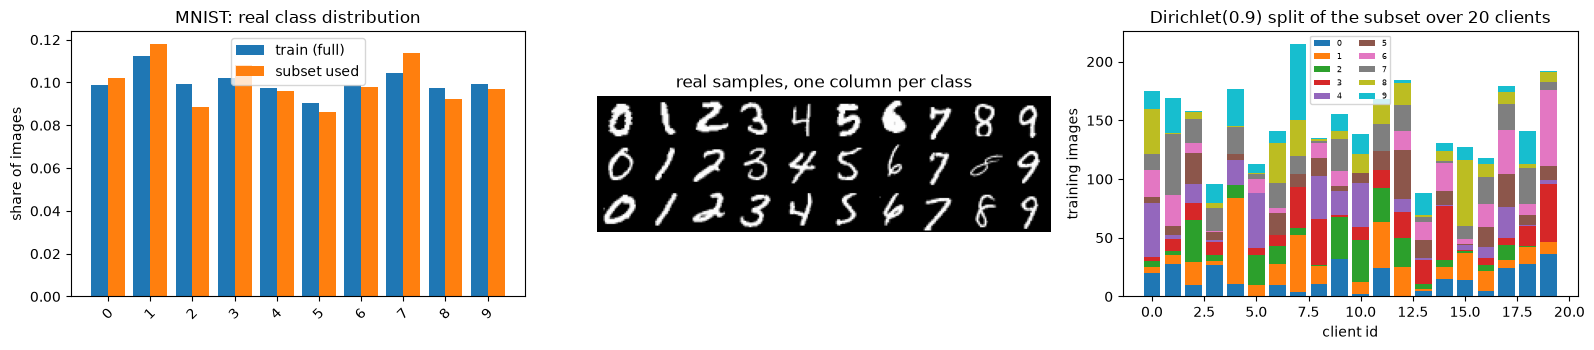

PCA(4) explained variance ratio: [0.1   0.071 0.063 0.053] (sum 0.287)


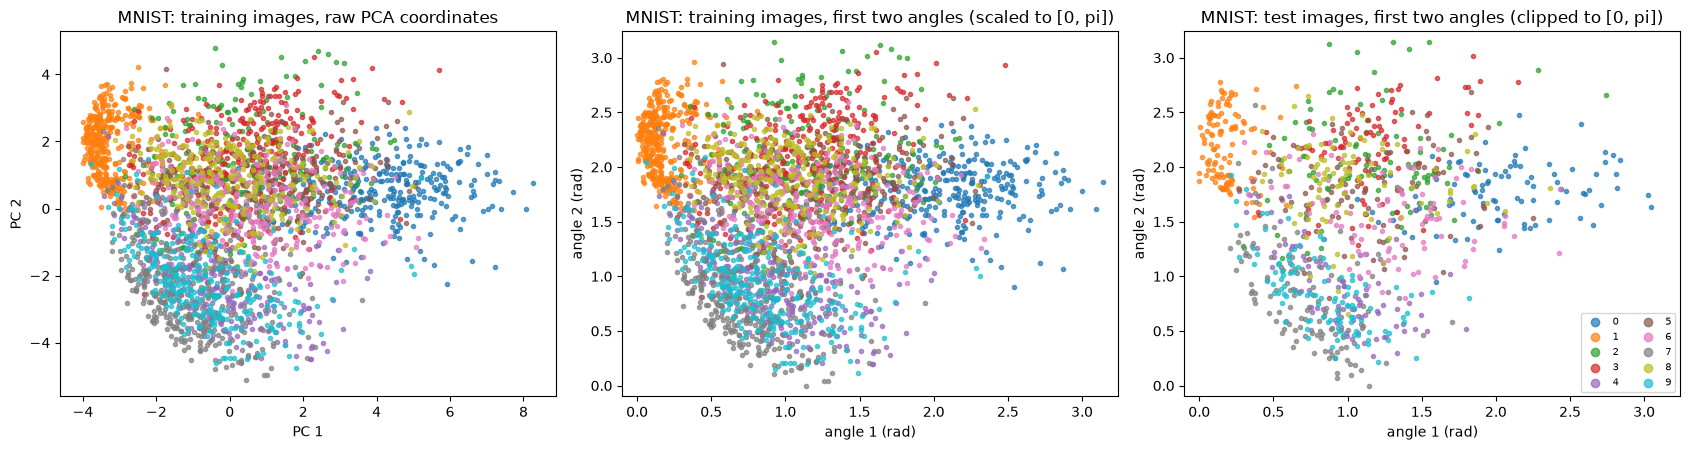

In [5]:
def explore(task, n_pca, title):
    classes = MNIST_CLASSES if task == "mnist" else CIFAR_CLASSES
    raw = RAW[task]
    fed = get_federation(task, SEEDS[0])
    Xtr, ytr, Xte, yte = fed["Xtr"], fed["ytr"], fed["Xte"], fed["yte"]
    print(f"=== {title} ===")
    print("full train split:", (len(raw['train']),) + tuple(Xtr.shape[1:]), "| full test split:", (len(raw['test']),) + tuple(Xte.shape[1:]),
          "| dtype uint8, pixel range 0-255")
    nfeat = int(np.prod(Xtr.shape[1:]))
    print(f"features: {nfeat} raw pixel intensities per image ({'28x28 grey, resized to 32x32 for the CNN' if task=='mnist' else '32x32x3 colour'});"
          f" the CNN front-end compresses them to {N_QUBITS if task=='mnist' else 8} rotation angles")
    print("original label values:", sorted(np.unique(raw['train'].labels).tolist()), "->", classes)
    cnt_tr = np.bincount(raw["train"].labels, minlength=10); cnt_te = np.bincount(raw["test"].labels, minlength=10)
    cnt_sub = np.bincount(ytr, minlength=10)
    print(pd.DataFrame({"class": classes, "train (full)": cnt_tr, "test (full)": cnt_te, f"train subset used (n={len(ytr)})": cnt_sub}).to_string(index=False))

    fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
    x = np.arange(10); w = 0.4
    ax[0].bar(x - w / 2, cnt_tr / cnt_tr.sum(), w, label="train (full)"); ax[0].bar(x + w / 2, cnt_sub / cnt_sub.sum(), w, label="subset used")
    ax[0].set_xticks(x); ax[0].set_xticklabels(classes, rotation=45); ax[0].set_ylabel("share of images"); ax[0].set_title(f"{title}: real class distribution"); ax[0].legend()
    # sample images (first 3 of each class)
    cols = 10; rows = 3
    grid = np.zeros((rows * Xtr.shape[1], cols * Xtr.shape[2]) + Xtr.shape[3:], dtype=np.uint8)
    for c in range(10):
        ids = np.where(ytr == c)[0][:rows]
        for r, i in enumerate(ids):
            grid[r * Xtr.shape[1]:(r + 1) * Xtr.shape[1], c * Xtr.shape[2]:(c + 1) * Xtr.shape[2]] = Xtr[i]
    ax[1].imshow(grid, cmap="gray" if task == "mnist" else None); ax[1].axis("off"); ax[1].set_title("real samples, one column per class")
    # Dirichlet client mixture
    mix = np.zeros((K_CLIENTS, 10))
    for ci in range(K_CLIENTS):
        idx = fed["loaders"].partition_list[ci]
        mix[ci] = np.bincount(fed["train_ds"].targets[idx].numpy(), minlength=10)
    bottom = np.zeros(K_CLIENTS)
    cmap = plt.get_cmap("tab10")
    for c in range(10):
        ax[2].bar(np.arange(K_CLIENTS), mix[:, c], bottom=bottom, color=cmap(c), label=classes[c]); bottom += mix[:, c]
    ax[2].set_xlabel("client id"); ax[2].set_ylabel("training images"); ax[2].set_title(f"Dirichlet({ALPHA}) split of the subset over {K_CLIENTS} clients")
    ax[2].legend(ncol=2, fontsize=6)
    plt.tight_layout(); plt.show()

    # PCA fitted on the training split only; raw coordinates, then angles in [0, pi]
    flat = lambda X: (X.reshape(len(X), -1).astype(np.float32) / 255.0)
    pca = PCA(n_components=n_pca, random_state=SEED).fit(flat(Xtr))
    Ztr, Zte = pca.transform(flat(Xtr)), pca.transform(flat(Xte))
    sc = MinMaxScaler((0, np.pi)).fit(Ztr)
    Atr, Ate = sc.transform(Ztr), np.clip(sc.transform(Zte), 0, np.pi)
    print(f"PCA({n_pca}) explained variance ratio: {np.round(pca.explained_variance_ratio_, 3)} (sum {pca.explained_variance_ratio_.sum():.3f})")
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
    def scat(a, P, y, ttl, xl, yl, lim=None):
        for c in range(10):
            m = y == c
            a.scatter(P[m, 0], P[m, 1], s=9, color=cmap(c), label=classes[c], alpha=0.7)
        a.set_title(ttl); a.set_xlabel(xl); a.set_ylabel(yl)
        if lim: a.set_xlim(*lim); a.set_ylim(*lim)
    scat(ax[0], Ztr, ytr, f"{title}: training images, raw PCA coordinates", "PC 1", "PC 2")
    scat(ax[1], Atr, ytr, f"{title}: training images, first two angles (scaled to [0, pi])", "angle 1 (rad)", "angle 2 (rad)", (-0.1, np.pi + 0.1))
    scat(ax[2], Ate, yte, f"{title}: test images, first two angles (clipped to [0, pi])", "angle 1 (rad)", "angle 2 (rad)", (-0.1, np.pi + 0.1))
    ax[2].legend(ncol=2, fontsize=7, markerscale=2)
    plt.tight_layout(); plt.show()
    return fed

fed_mnist = explore("mnist", N_QUBITS, "MNIST")

=== CIFAR-10 ===
full train split: (50000, 32, 32, 3) | full test split: (10000, 32, 32, 3) | dtype uint8, pixel range 0-255
features: 3072 raw pixel intensities per image (32x32x3 colour); the CNN front-end compresses them to 8 rotation angles
original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] -> ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
     class  train (full)  test (full)  train subset used (n=3000)
  airplane          5000         1000                         302
automobile          5000         1000                         300
      bird          5000         1000                         309
       cat          5000         1000                         278
      deer          5000         1000                         298
       dog          5000         1000                         284
      frog          5000         1000                         321
     horse          5000         1000                         309
      ship   

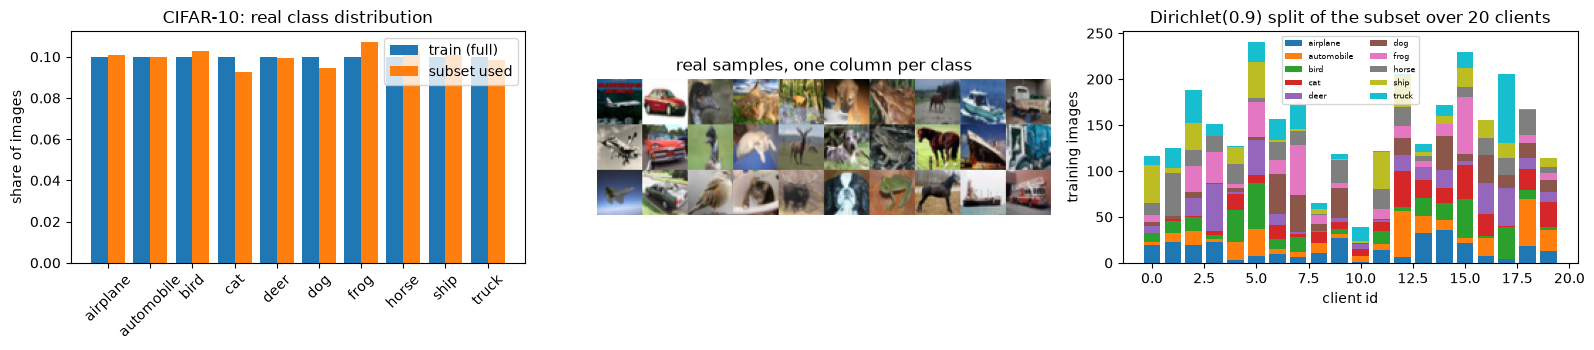

PCA(8) explained variance ratio: [0.289 0.111 0.07  0.039 0.038 0.027 0.027 0.021] (sum 0.621)


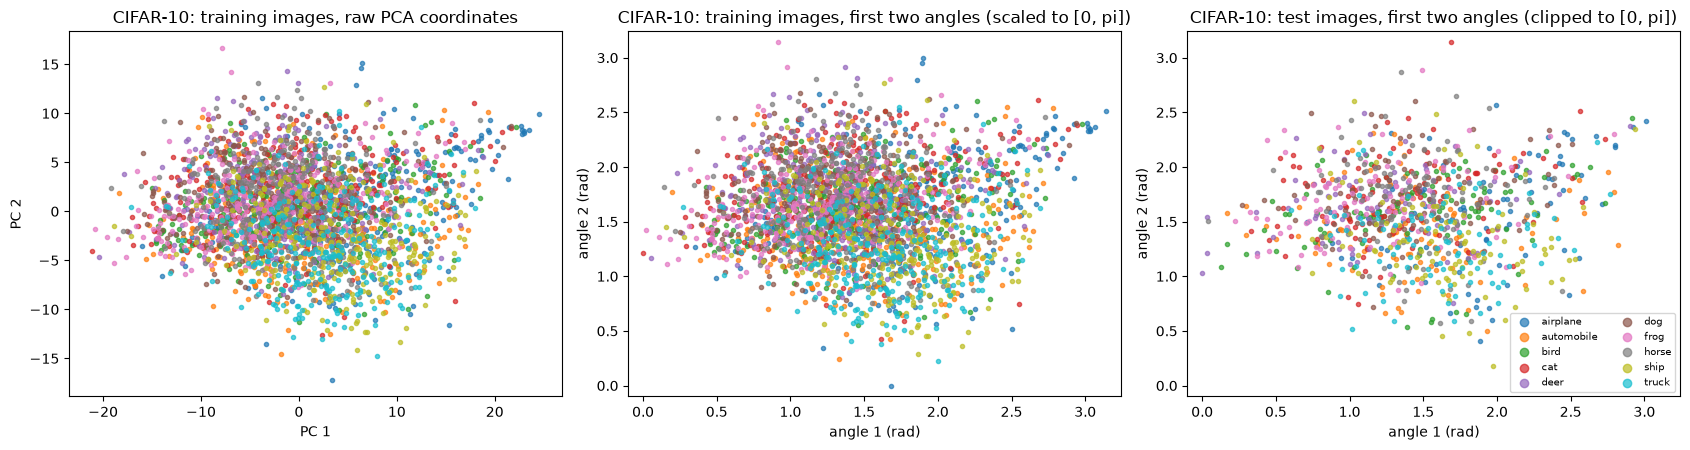

In [6]:
# CIFAR-10 (the authors' CIFAR QNet uses 8 data qubits + 1 ancilla)
fed_cifar = explore("cifar", 8, "CIFAR-10")

## Quantum Circuit Architecture

The hybrid QNN of the paper is `Conv(1->6) -> Conv(6->16) -> Linear(576->4) -> [quantum layer] -> Linear(4->32) -> Linear(32->10)` for MNIST. The quantum layer is a PennyLane QNode on **5 wires**: wires 0-3 are the data qubits and wire 4 is the ancilla used by the attacks.

* **Clean circuit** (what every honest client runs): `AngleEmbedding` of the 4 CNN outputs (RX rotations), then `BasicEntanglerLayers` with 6 layers (an RX rotation on every data qubit followed by a ring of CNOTs), then `<Z>` on wires 0-3. Trainable parameters: 6 x 4 = 24. The ancilla is idle.
* **Backdoored circuits** (what a malicious client swaps in for a whole poisoned round): the same embedding (RY rotations for the Grover circuit), then a *flag*: a multi-controlled X that flips the ancilla when the data register equals the marked bit-string, a *payload* that runs only under control of the ancilla (Grover diffusion / Pauli rotations / truncated QFT with a CNOT / 2-qubit QFT with RZ and CZ, followed by the same entangling ansatz), and finally the flag is applied again to "uncompute" the ancilla. These are the authors' circuits, drawn straight from `tasks/mnist.py`.

**Assumptions the paper leaves open (taken from the authors' code):** marked state [1, 0, 1, 0]; Pauli-trigger angles [0.2, 1.3, 2.0, 0.5] (the flag bits are `int(10 a) mod 2` = [0, 1, 0, 1]); QFT period 3; phase 0.25; the paper's "Entangle (x6)" is `BasicEntanglerLayers`. Because the payload also acts on the data wires, the second flag does not exactly restore the ancilla; we keep the circuit as published.

The drawings below are made with `qml.draw_mpl` from the **QNode objects that the authors' code builds**, so they are the executed circuits. Qubit count and depth come from `qml.specs` (depth after decomposition into elementary gates); trainable parameters are the entries of the `weights` tensor.

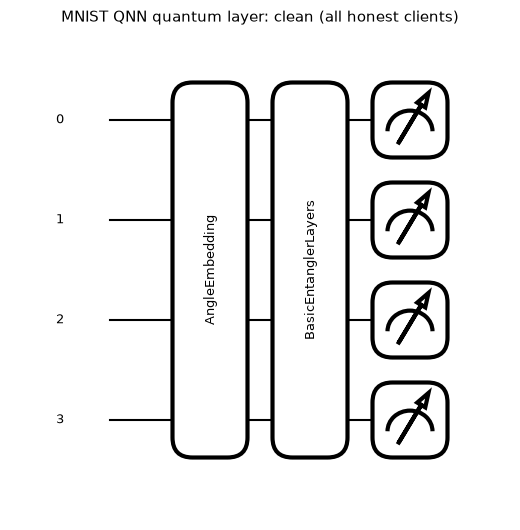

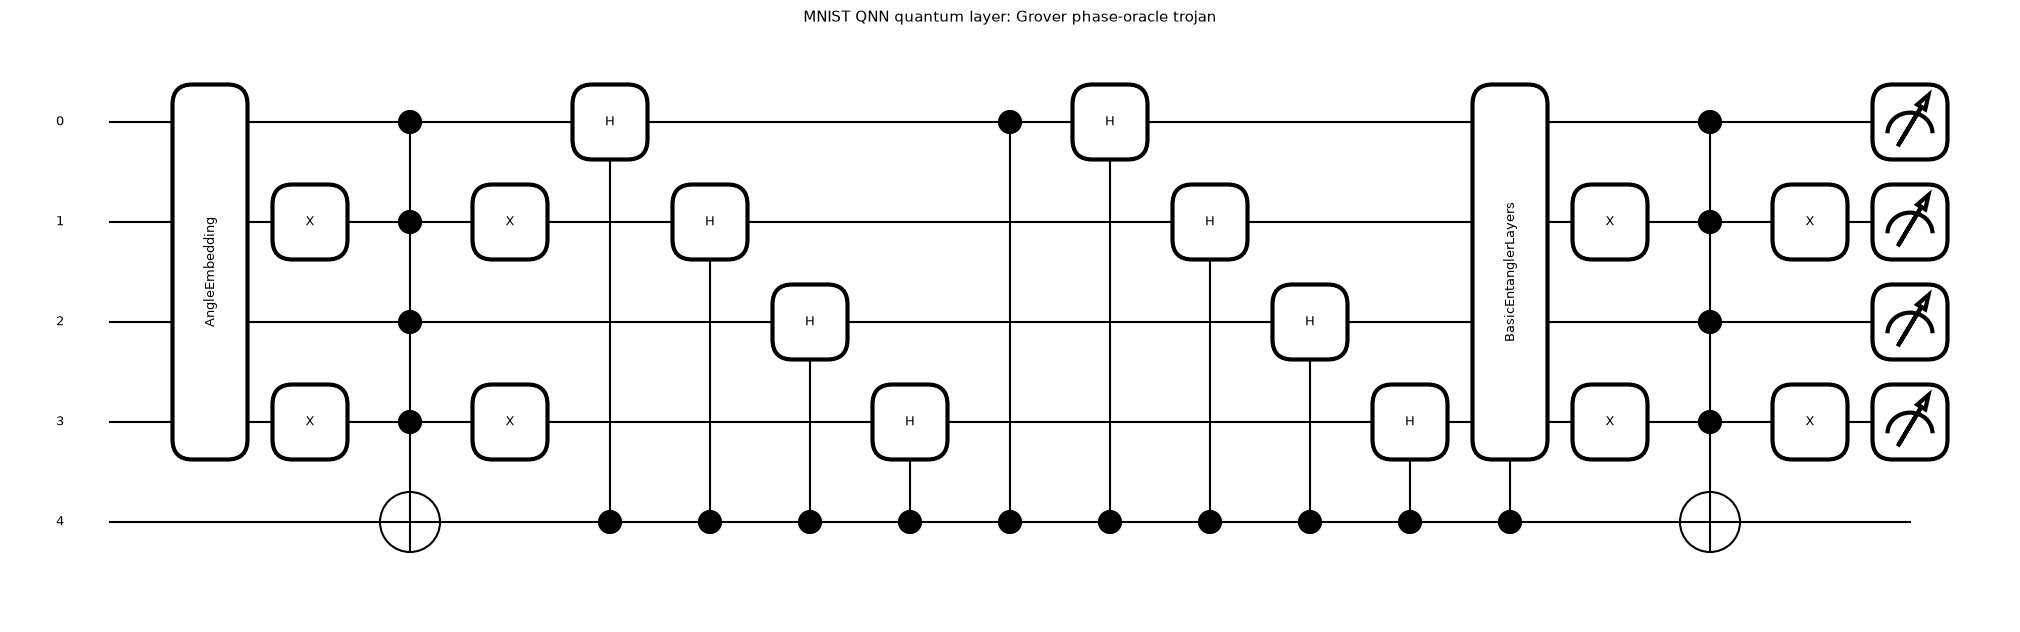

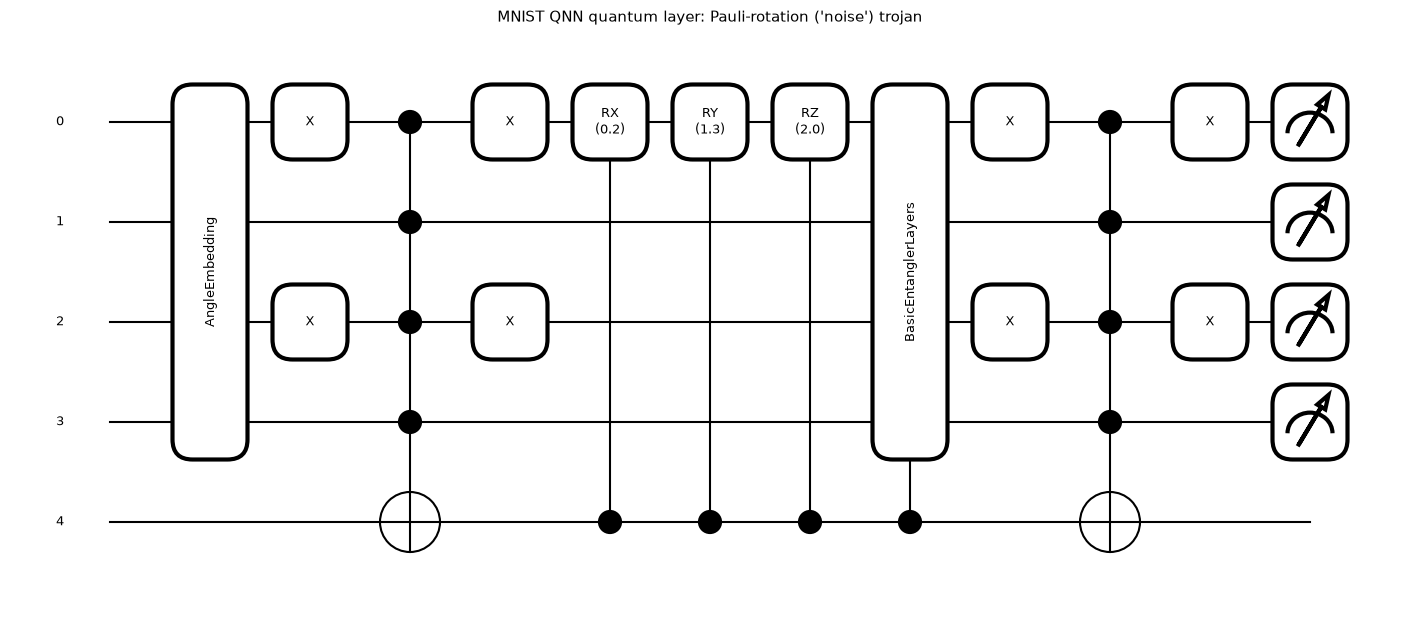

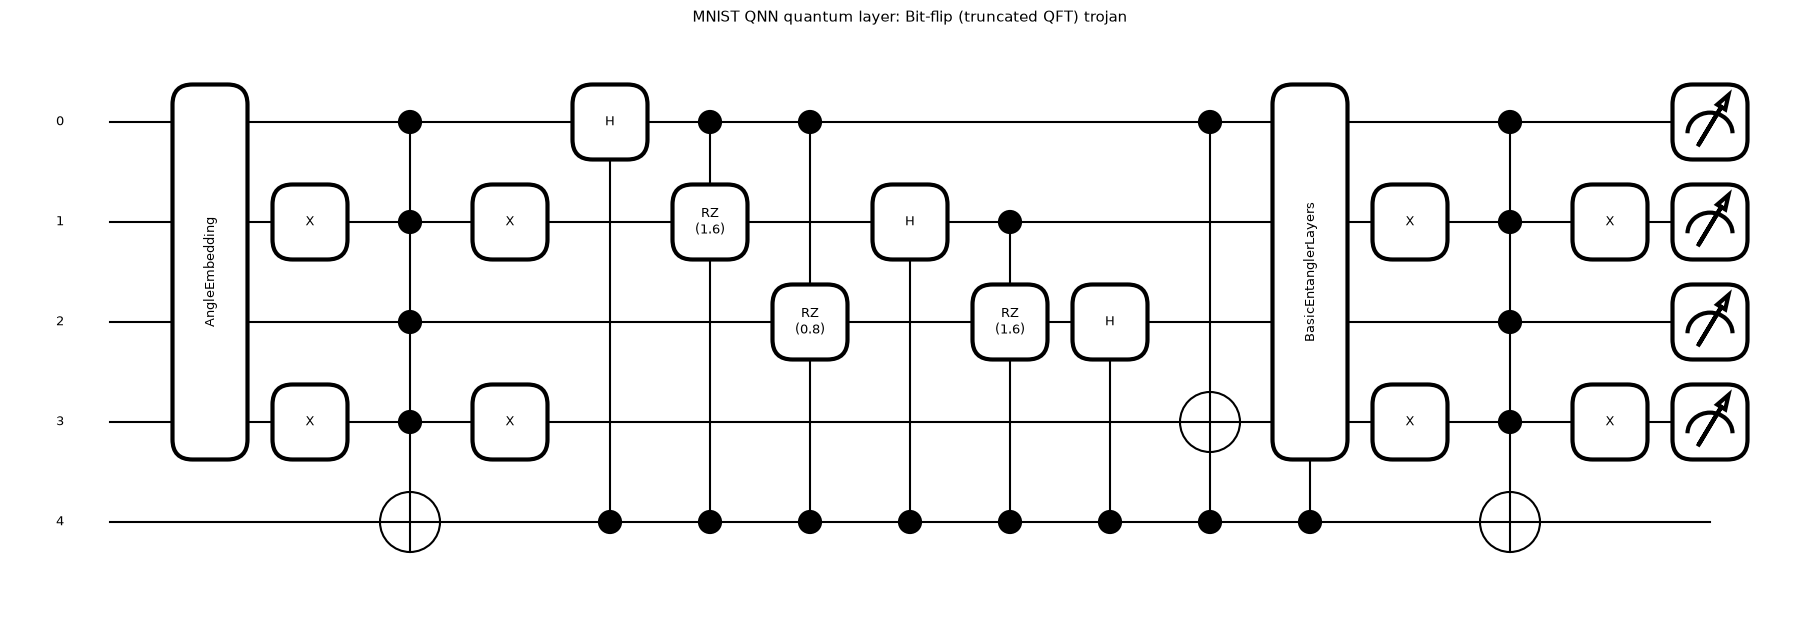

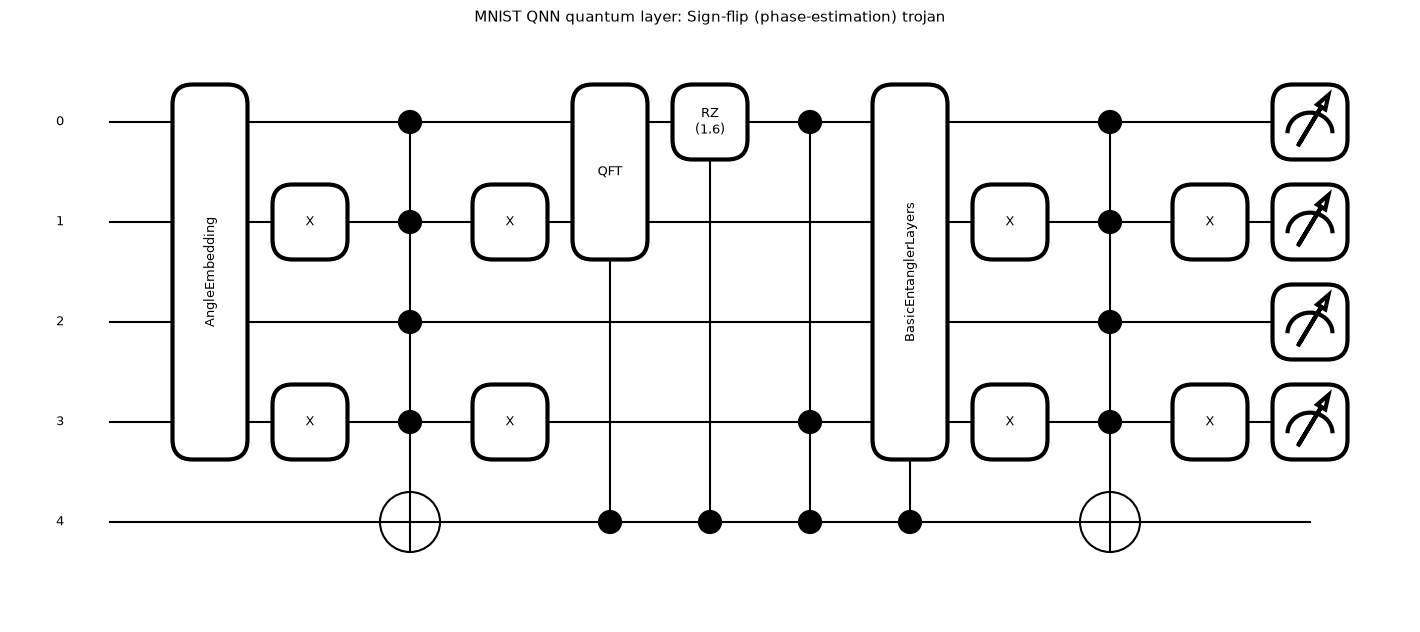

                            circuit  qubits used  depth (elementary gates)  gates  trainable parameters
         clean (all honest clients)            4                        31     52                    24
         Grover phase-oracle trojan            5                        63     71                    24
    Pauli-rotation ('noise') trojan            5                        58     65                    24
    Bit-flip (truncated QFT) trojan            5                        61     69                    24
Sign-flip (phase-estimation) trojan            5                        58     65                    24

Entangling depth of the ansatz = 6 layers, parameters per layer = 4


In [7]:
MARK, ANGLES = [1, 0, 1, 0], [0.2, 1.3, 2.0, 0.5]
mnist_circuits = {
    "clean (all honest clients)": R_mnist.quantum_circuit,
    "Grover phase-oracle trojan": R_mnist.qnode_grover(MARK),
    "Pauli-rotation ('noise') trojan": R_mnist.qnode_noise(ANGLES),
    "Bit-flip (truncated QFT) trojan": R_mnist.qnode_bitflip(3, MARK),
    "Sign-flip (phase-estimation) trojan": R_mnist.qnode_signflip(0.25, MARK),
}
rows = []
for title, qn in mnist_circuits.items():
    inputs = torch.tensor([0.3, 1.1, 2.0, 2.9]); weights = torch.rand(Q_DEPTH, N_QUBITS) * 2 * np.pi
    fig, ax = qml.draw_mpl(qn, decimals=1, fontsize=9)(inputs, weights)
    fig.suptitle(f"MNIST QNN quantum layer: {title}", y=1.02, fontsize=11)
    plt.show()
    spec = qml.specs(qn, level="device")(inputs, weights)
    res = spec["resources"]
    rows.append({"circuit": title, "qubits used": res.num_allocs, "depth (elementary gates)": res.depth,
                 "gates": res.num_gates, "trainable parameters": int(weights.numel())})
print(pd.DataFrame(rows).to_string(index=False))
print("\nEntangling depth of the ansatz = %d layers, parameters per layer = %d" % (Q_DEPTH, N_QUBITS))

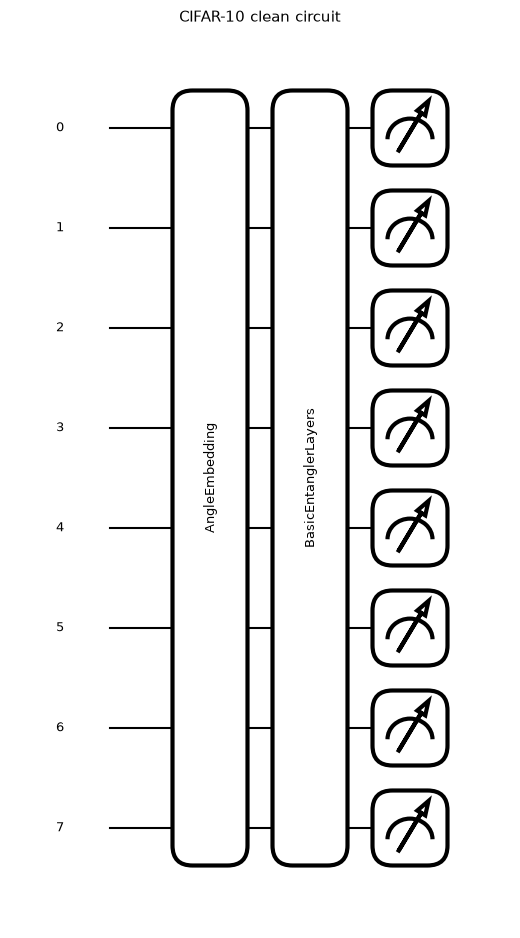

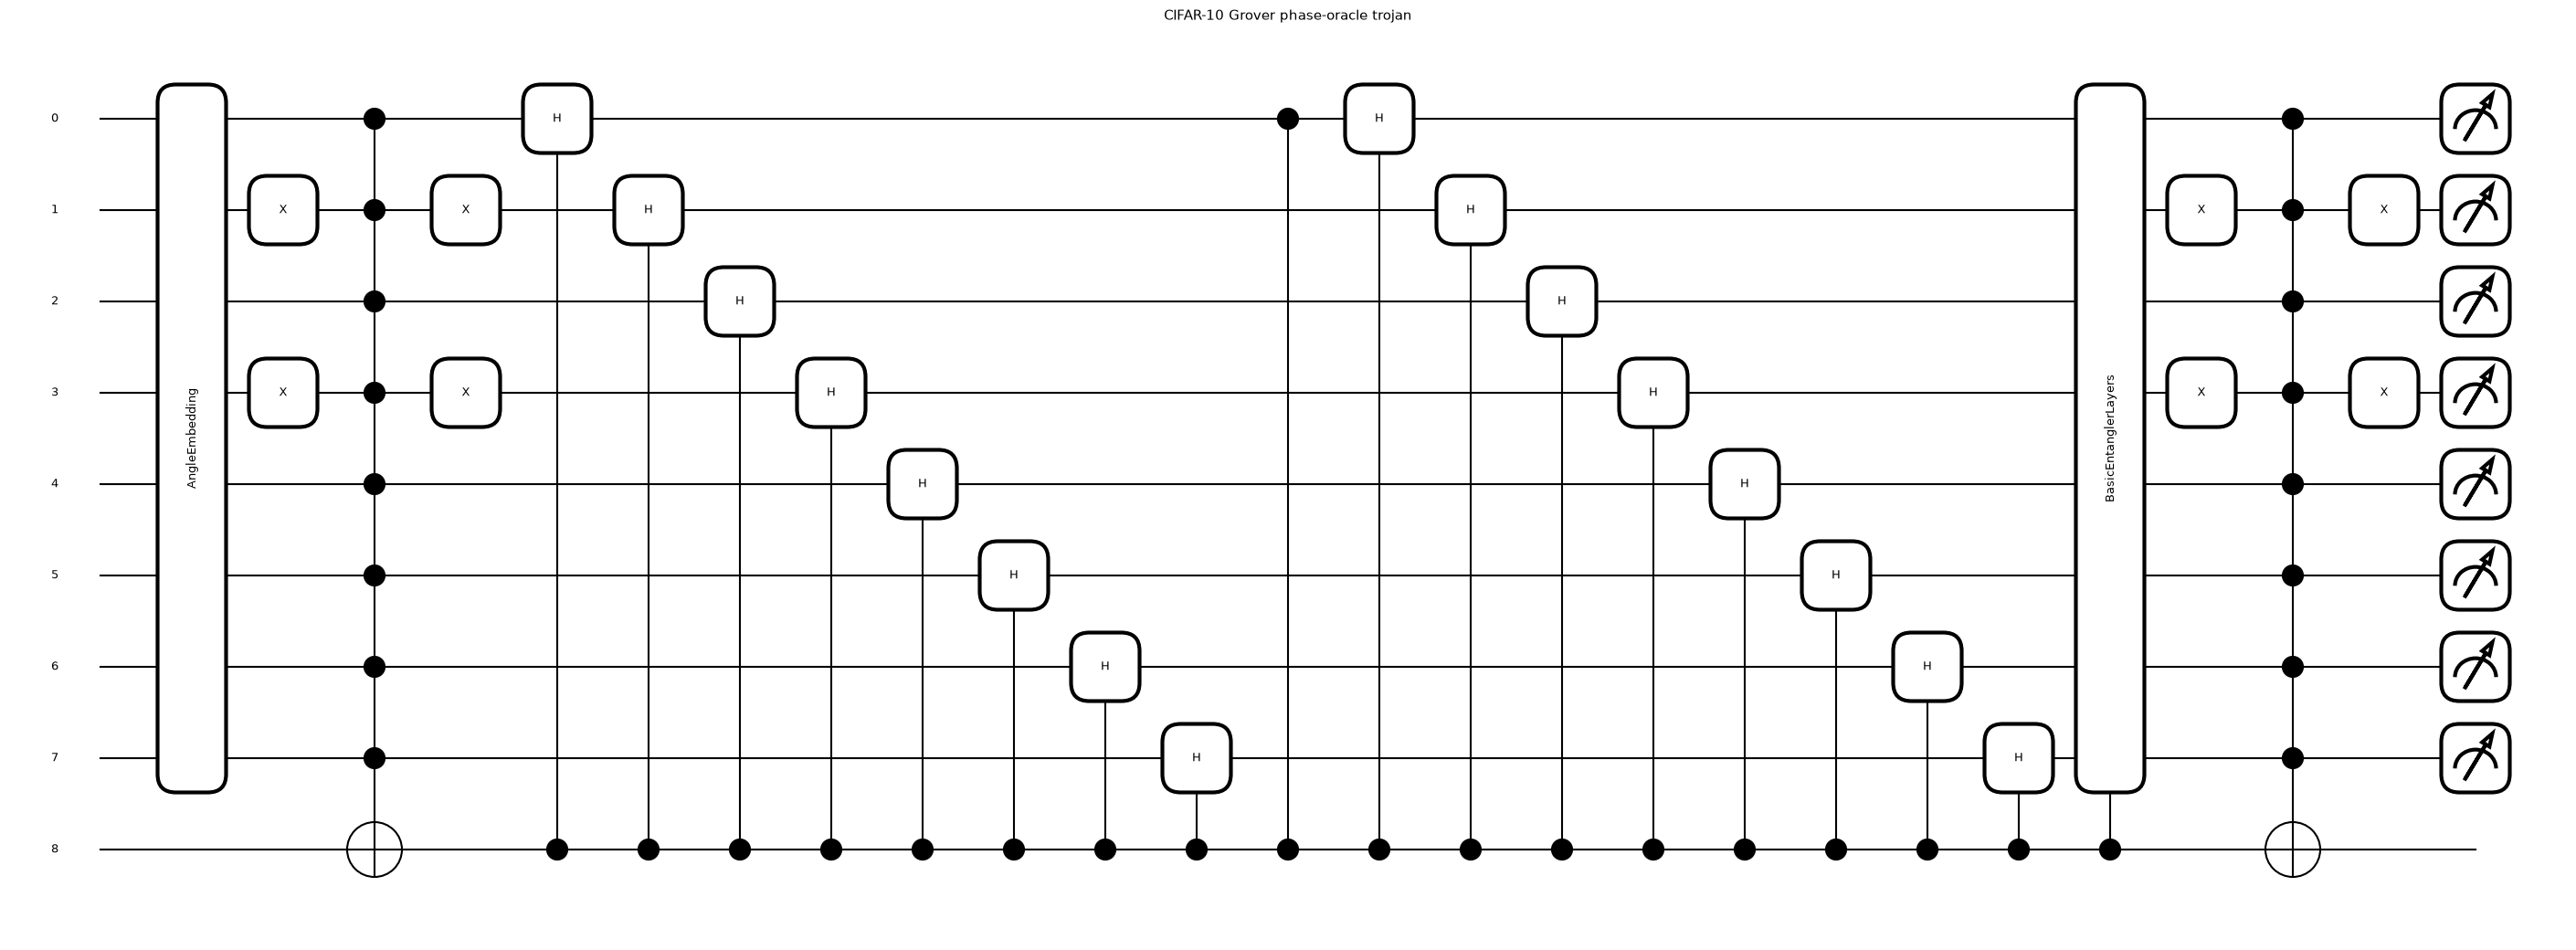

                            circuit  qubits used  depth (elementary gates)  gates  trainable parameters
             CIFAR-10 clean circuit            8                        37     72                    32
CIFAR-10 Grover phase-oracle trojan            9                        86     99                    32

The CIFAR-10 Pauli, Bit-flip and Sign-flip trojans of the authors' tasks/cifar.py are examined (and found defective) in the smoke-test section.


In [8]:
# CIFAR-10 circuits (8 data qubits + 1 ancilla, entangling depth 4), straight from the authors' tasks/cifar.py
cifar_circuits = {"CIFAR-10 clean circuit": R_cifar.quantum_circuit,
                  "CIFAR-10 Grover phase-oracle trojan": R_cifar.qnode_grover([1, 0, 1, 0])}
rows = []
for title, qn in cifar_circuits.items():
    inputs = torch.rand(8) * np.pi; weights = torch.rand(R_cifar.q_depth, R_cifar.n_qubits) * 2 * np.pi
    fig, ax = qml.draw_mpl(qn, decimals=1, fontsize=9)(inputs, weights)
    fig.suptitle(title, y=1.02, fontsize=11); plt.show()
    res = qml.specs(qn, level="device")(inputs, weights)["resources"]
    rows.append({"circuit": title, "qubits used": res.num_allocs, "depth (elementary gates)": res.depth, "gates": res.num_gates,
                 "trainable parameters": int(weights.numel())})
print(pd.DataFrame(rows).to_string(index=False))
print("\nThe CIFAR-10 Pauli, Bit-flip and Sign-flip trojans of the authors' tasks/cifar.py are examined (and found defective) in the smoke-test section.")

### A fast, exact stand-in for the PennyLane layer (used for the federated runs)

A PennyLane `default.qubit` call costs about 0.1-0.25 s per training step regardless of batch size (Python overhead of tape construction), so a 20-client federation for 25 rounds with 4 attack circuits and 6 aggregators would take days. The circuit that follows the embedding does not depend on the input, so its unitary `U(weights)` (32 x 32 for 5 qubits) can be built once per call and applied to the whole batch of product states. `FastQLayer` does exactly this with PyTorch complex tensors, keeps the parameter name `weights` of `qml.qnn.TorchLayer` (state dicts are interchangeable) and uses PennyLane itself to generate the constant gate blocks (Hadamards, QFT, controlled rotations, CNOT ring).

The next cell **asserts** that `FastQLayer` equals the authors' QNodes for all five circuits, for outputs and for gradients with respect to weights and inputs, and that the whole hybrid network (`FastQNet` vs the authors' `QNet`) gives the same logits and loss gradients when the quantum layer is swapped for a trojan, exactly as a malicious client does. The federated runs use the authors' `Server`, `Client` and `Attacker_QuantumTrojan` unchanged; only the model class differs.

In [9]:
CD = torch.complex128

def _const(fn, n):
    """2^n x 2^n matrix of a fixed gate sequence on wires 0..n-1, generated by PennyLane."""
    return torch.tensor(np.array(qml.matrix(fn, wire_order=list(range(n)))()), dtype=CD)

def _rx_layers(w):                       # (L, n) -> (L, n, 2, 2) RX matrices
    c, s = torch.cos(w / 2).to(CD), torch.sin(w / 2).to(CD)
    return torch.stack([torch.stack([c, -1j * s], -1), torch.stack([-1j * s, c], -1)], -2)

def _kron_n(R):                          # (L, n, 2, 2) -> (L, 2^n, 2^n), wire 0 most significant
    L, n = R.shape[:2]
    K = R[:, 0]
    for i in range(1, n):
        K = torch.einsum("lab,lcd->lacbd", K, R[:, i]).reshape(L, K.shape[1] * 2, K.shape[2] * 2)
    return K

class FastQLayer(nn.Module):
    """Exact batched torch version of the QNodes in the authors' tasks/mnist.py (n data wires + 1 ancilla wire).
    kind: clean | grover | noise | bitflip | signflip."""
    def __init__(self, n_qubits, depth, kind="clean", **kw):
        super().__init__()
        n = self.n = n_qubits; self.kind = kind
        self.weights = nn.Parameter(torch.empty(depth, n))
        nn.init.uniform_(self.weights, 0.0, 2 * math.pi)            # same init as qml.qnn.TorchLayer
        def ring():                                                # CNOT ring of BasicEntanglerLayers
            if n == 2: qml.CNOT(wires=[0, 1])
            elif n > 2:
                for i in range(n): qml.CNOT(wires=[i, (i + 1) % n])
        self.register_buffer("ring", _const(ring, n), persistent=False)
        if kind != "clean":
            if kind == "noise":
                a = kw["trigger_angles"]; marked = [int(v * 10) % 2 for v in a]
                def p0():
                    qml.RX(float(a[0]), wires=0); qml.RY(float(a[1]), wires=0); qml.RZ(float(a[2]), wires=0)
            elif kind == "grover":
                marked = list(kw["marked_state"])
                def p0():
                    for w in range(n): qml.Hadamard(w)
                    qml.PauliZ(0)
                    for w in range(n): qml.Hadamard(w)
            elif kind == "bitflip":
                marked = list(kw["marked_state"]); per = kw["period"]
                def p0():
                    for j in range(per):
                        qml.Hadamard(j)
                        for k in range(1, per - j):
                            qml.CRZ(math.pi / 2 ** k, wires=[j, j + k])
                    qml.CNOT(wires=[0, n - 1])
            elif kind == "signflip":
                marked = list(kw["marked_state"]); ph = kw["phase"]
                def p0():
                    qml.QFT(wires=[0, 1]); qml.RZ(2 * math.pi * ph, wires=0); qml.CZ(wires=[0, n - 1])
            self.register_buffer("P0", _const(p0, n), persistent=False)
            Fm = torch.eye(2 ** (n + 1), dtype=CD)                  # flag: flip the ancilla iff data register == marked
            m = int("".join(str(b) for b in marked), 2)
            Fm[[2 * m, 2 * m + 1]] = Fm[[2 * m + 1, 2 * m]]
            self.register_buffer("F", Fm, persistent=False)

    def _bel(self):                                                # BasicEntanglerLayers(weights) on the data wires
        K = _kron_n(_rx_layers(self.weights))
        D = torch.eye(2 ** self.n, dtype=CD)
        for l in range(K.shape[0]):
            D = self.ring @ K[l] @ D                               # RX layer first, then the CNOT ring
        return D

    def unitary(self):
        D = self._bel()
        if self.kind == "clean":
            return torch.kron(D, torch.eye(2, dtype=CD))
        P = D @ self.P0                                            # payload, then ansatz
        e00 = torch.tensor([[1, 0], [0, 0]], dtype=CD); e11 = torch.tensor([[0, 0], [0, 1]], dtype=CD)
        C = torch.kron(torch.eye(2 ** self.n, dtype=CD), e00) + torch.kron(P, e11)   # payload controlled on the ancilla
        return self.F @ C @ self.F                                 # flag, controlled payload, flag again

    def forward(self, x):
        n = self.n
        x2 = x.reshape(-1, n).to(torch.float64)
        c, s = torch.cos(x2 / 2).to(CD), torch.sin(x2 / 2).to(CD)
        a1 = s if self.kind == "grover" else -1j * s               # RY|0> = (c, s); RX|0> = (c, -i s)
        psi = torch.ones(x2.shape[0], 1, dtype=CD)
        for w in range(n):
            psi = (psi[:, :, None] * torch.stack([c[:, w], a1[:, w]], 1)[:, None, :]).reshape(x2.shape[0], -1)
        psi = torch.stack([psi, torch.zeros_like(psi)], -1).reshape(x2.shape[0], -1)   # ancilla starts in |0>
        out = psi @ self.unitary().T
        p = (out.conj() * out).real.reshape(-1, *([2] * (n + 1)))
        z = []
        for i in range(n):                                         # <Z_i> on the data wires
            q = p.movedim(1 + i, -1).reshape(p.shape[0], -1, 2).sum(1)
            z.append(q[:, 0] - q[:, 1])
        return torch.stack(z, 1).to(x.dtype).reshape(*x.shape[:-1], n)

class FastQNet(nn.Module):
    """Same classical layers and forward as the authors' tasks.mnist.QNet; quantum layers are FastQLayer."""
    def __init__(self, n_qubits=N_QUBITS, q_depth=Q_DEPTH):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, 3); self.conv2 = nn.Conv2d(6, 16, 3); self.fc1 = nn.Linear(16 * 6 * 6, n_qubits)
        self.q_layer = FastQLayer(n_qubits, q_depth, "clean")
        self.q_layer_grover = lambda marked_state: FastQLayer(n_qubits, q_depth, "grover", marked_state=marked_state)
        self.q_layer_noise = lambda trigger_angles: FastQLayer(n_qubits, q_depth, "noise", trigger_angles=trigger_angles)
        self.q_layer_bitflip = lambda period, marked_state: FastQLayer(n_qubits, q_depth, "bitflip", period=period, marked_state=marked_state)
        self.q_layer_signflip = lambda phase, marked_state: FastQLayer(n_qubits, q_depth, "signflip", phase=phase, marked_state=marked_state)
        self.fc2 = nn.Linear(n_qubits, 32); self.fc3 = nn.Linear(32, 10)
    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        x = F.relu(self.fc1(x.view(-1, 16 * 6 * 6)))
        x = self.q_layer(x)
        return self.fc3(F.relu(self.fc2(x)))

class ClassicalTwinNet(FastQNet):
    """Classical twin: the quantum layer is replaced by a classical 4->4 linear layer + tanh (same bottleneck width)."""
    def __init__(self):
        super().__init__()
        self.q_layer = nn.Sequential(nn.Linear(N_QUBITS, N_QUBITS), nn.Tanh())

# ---------------------------------------------------------------- equivalence checks (assertions)
torch.manual_seed(0)
x = torch.rand(16, 4) * 6 - 3
ref = R_mnist.QNet()
cases = {"clean": (ref.q_layer, dict(kind="clean")),
         "grover": (ref.q_layer_grover(MARK), dict(kind="grover", marked_state=MARK)),
         "noise": (ref.q_layer_noise(ANGLES), dict(kind="noise", trigger_angles=ANGLES)),
         "bitflip": (ref.q_layer_bitflip(3, MARK), dict(kind="bitflip", period=3, marked_state=MARK)),
         "signflip": (ref.q_layer_signflip(0.25, MARK), dict(kind="signflip", phase=0.25, marked_state=MARK))}
rows = []
for name, (pl_layer, kw) in cases.items():
    fl = FastQLayer(N_QUBITS, Q_DEPTH, **kw)
    with torch.no_grad(): fl.weights.copy_(pl_layer.weights)
    xa, xb = x.clone().requires_grad_(True), x.clone().requires_grad_(True)
    ya, yb = pl_layer(xa), fl(xb)
    ya.pow(2).sum().backward(); yb.pow(2).sum().backward()
    e = dict(output=(ya - yb).abs().max().item(), grad_weights=(pl_layer.weights.grad - fl.weights.grad).abs().max().item(),
             grad_inputs=(xa.grad - xb.grad).abs().max().item())
    assert max(e.values()) < 1e-5, (name, e)
    rows.append({"circuit": name, **{k: f"{v:.1e}" for k, v in e.items()}, "differs from clean?": bool((ya - ref.q_layer(x)).abs().max() > 1e-2)})
print("max |PennyLane - FastQLayer| (all < 1e-5, asserted):")
print(pd.DataFrame(rows).to_string(index=False))

# whole network: swap the quantum layer for a trojan exactly as the malicious client does
fq = FastQNet()
sd = {k: v for k, v in ref.state_dict().items()}
fq.load_state_dict(sd)                                          # identical conv/fc/quantum weights
img = torch.randn(8, 1, 32, 32); tgt = torch.randint(0, 10, (8,))
for name in ["clean", "grover", "bitflip"]:
    if name == "clean":
        la, lb = ref.q_layer, fq.q_layer
    else:
        la = getattr(ref, f"q_layer_{name}")(MARK) if name == "grover" else ref.q_layer_bitflip(3, MARK)
        lb = getattr(fq, f"q_layer_{name}")(MARK) if name == "grover" else fq.q_layer_bitflip(3, MARK)
        with torch.no_grad(): lb.weights.copy_(la.weights)
    ref.q_layer, fq.q_layer = la, lb
    ref.zero_grad(); fq.zero_grad()
    oa, ob = ref(img), fq(img)
    F.cross_entropy(oa, tgt).backward(); F.cross_entropy(ob, tgt).backward()
    gd = max((pa.grad - pb.grad).abs().max().item() for (na, pa), (nb, pb) in zip(ref.named_parameters(), fq.named_parameters()) if pa.grad is not None)
    print(f"QNet vs FastQNet with {name:7s} quantum layer: max logit diff {(oa - ob).abs().max().item():.1e}, max parameter-gradient diff {gd:.1e}")
    assert (oa - ob).abs().max().item() < 1e-4 and gd < 1e-4
print("parameter names identical:", [n for n, _ in ref.named_parameters()] == [n for n, _ in fq.named_parameters()])
print("FastQNet trainable parameters:", sum(p.numel() for p in FastQNet().parameters()))

max |PennyLane - FastQLayer| (all < 1e-5, asserted):
 circuit  output grad_weights grad_inputs  differs from clean?
   clean 6.0e-08      9.5e-07     6.0e-08                False
  grover 1.2e-07      5.6e-08     3.6e-07                 True
   noise 1.2e-07      5.2e-08     6.0e-07                 True
 bitflip 1.2e-07      1.5e-08     3.6e-07                 True
signflip 1.2e-07      3.0e-08     3.6e-07                 True
QNet vs FastQNet with clean   quantum layer: max logit diff 3.0e-08, max parameter-gradient diff 7.5e-09


QNet vs FastQNet with grover  quantum layer: max logit diff 6.0e-08, max parameter-gradient diff 1.9e-08
QNet vs FastQNet with bitflip quantum layer: max logit diff 6.0e-08, max parameter-gradient diff 1.9e-08
parameter names identical: True
FastQNet trainable parameters: 3762


## Federated training machinery

`run_fl` below wires the authors' components together exactly as their `_main.py` does (it cannot be called directly because it expects a command line and TensorBoard):

* K = 20 clients, each with its own optimiser (AdamW), one `Client` per honest participant and one `Attacker_QuantumTrojan` per malicious participant (`attack_type` = grover / noise / bitflip / signflip, trigger parameters as in `_main.py`, poison ratio rho = 0.9);
* each round: `server.distribute()`, `server.train(all clients)` (local training, update, robust aggregation), `server.test()`;
* aggregators: `fedavg`, `krum`, `mkrum`, `foolsgold`, `mudhog` (the authors' `Server.set_AR`) and `flguardian` (their `FLGuardianDefense` screening followed by FedAvg, as in `Server.train`).

We add only bookkeeping: a thin subclass of the malicious client that records the L2 norm of the update it actually transmits (this does not change its behaviour), and the L2 norm of every honest update. Each run is cached as JSON in `DATA_DIR/results`, so repeating a cell is free and an interrupted notebook resumes.

Malicious clients are drawn at random (seeded) among clients that own data, and the sets are nested across q (the first 1 of the permutation for q = 5 %, the first 4 for 20 %, the first 10 for 50 %). Accuracy is the accuracy of the global model on the test subset after the last round (we also store the mean of the last three rounds because a single round is noisy).

In [10]:
TRIG = {"grover": [1, 0, 1, 0], "noise": [0.2, 1.3, 2.0, 0.5], "bitflip": [3, [1, 0, 1, 0]], "signflip": [0.25, [1, 0, 1, 0]]}   # authors' _main.py

class LoggedAttacker(Attacker_QuantumTrojan):
    """Authors' malicious client; only records the norm of the update it returns (behaviour unchanged)."""
    def getDelta(self):
        out = super().getDelta()
        self.sent_norm = float(R_utils.net2vec(out).norm())
        return out

class SafeFLGuardian(FLGuardianDefense):
    """Authors' FLGuardian; if its trust threshold would remove every client we keep all of them (CHOICE)."""
    def filter_clients(self, clients, suspicious_ids):
        kept = super().filter_clients(clients, suspicious_ids)
        return kept if len(kept) > 0 else list(clients)

def n_attackers(q, k=None):
    k = k or K_CLIENTS
    return 0 if q <= 0 else max(1, int(round(q * k)))

def run_fl(task="mnist", model="quantum", attack="grover", q=0.0, agg="fedavg", seed=1, rounds=None, lr=None, k=None,
           n_train=None, n_test=None, tag="", save_model=True):
    """One federated run with the authors' Server/Client/Attacker classes. Returns a dict of per-round results."""
    rounds = rounds or ROUNDS; lr = lr or LR; k = k or K_CLIENTS
    n_att = n_attackers(q, k) if model in ("quantum", "pennylane") else 0
    key = f"{task}_{model}_{attack if n_att else 'clean'}_q{n_att}of{k}_{agg}_s{seed}_r{rounds}_n{n_train or N_TRAIN}_lr{lr}{tag}"
    path = DATA_DIR / "results" / (key + ".json")
    if path.exists():
        return json.load(open(path))
    fed = get_federation(task, seed, k=k, n_train=n_train, n_test=n_test)
    loaders = fed["loaders"]
    torch.manual_seed(seed); random.seed(seed); np.random.seed(seed)
    if task == "mnist":
        Net = {"quantum": FastQNet, "classical_twin": ClassicalTwinNet, "lenet": R_mnist.Net, "pennylane": R_mnist.QNet}[model]
    else:
        Net = R_cifar.QNet
    server = Server(Net(), fed["test"], F.cross_entropy, "cpu")
    server.set_AR("fedavg" if agg == "flguardian" else agg)
    server.set_log_path(str(DATA_DIR / "logs"), "run", "t")
    if agg == "flguardian":
        server.use_flguardian = True
        server.flguardian = SafeFLGuardian(n_clusters=2, use_cosine_and_euclidean=True, layer_weighting="quadratic",
                                           trust_threshold=0.5, top_k=None, random_state=42)
    if task == "cifar" and agg == "mudhog":
        server.set_AR_param(dbscan_eps=18, min_samples=12)      # as in the authors' _main.py
    # malicious clients: seeded permutation of the clients that own data, nested across q
    sizes = [len(loaders[i].dataset) for i in range(k)]
    perm = np.random.default_rng(1000 + seed).permutation([i for i in range(k) if sizes[i] > 0])
    mal = set(int(i) for i in perm[:n_att])
    for i in range(k):
        m = Net()
        opt = torch.optim.AdamW(m.parameters(), lr=lr)
        if i in mal:
            c = LoggedAttacker(i, m, loaders[i], opt, F.cross_entropy, "cpu", inner_epochs=LOCAL_EPOCHS, attack_type=attack,
                               trigger_params=TRIG[attack], poison_frac=RHO, num_attackers=max(1, n_att))
        else:
            c = Client(i, m, loaders[i], opt, F.cross_entropy, "cpu", LOCAL_EPOCHS)
        server.attach(c)
    acc, ben, mal_sent, mal_raw = [], [], [], []
    t0 = time.time()
    for r in range(rounds):
        server.distribute()
        server.train(range(k))
        acc.append(float(server.test()[1]))
        ben.append(float(np.mean([R_utils.net2vec(c.stateChange).norm().item() for c in server.clients if c.cid not in mal and sizes[c.cid] > 0])))
        if mal:
            mal_sent.append(float(np.mean([c.sent_norm for c in server.clients if c.cid in mal])))
            mal_raw.append(float(np.mean([R_utils.net2vec(c.stateChange).norm().item() for c in server.clients if c.cid in mal])))
    res = dict(key=key, task=task, model=model, attack=attack if n_att else None, q=n_att / k, n_att=n_att, agg=agg, seed=seed,
               rounds=rounds, acc=acc, final=acc[-1], last3=float(np.mean(acc[-3:])), benign_norm=ben, mal_sent_norm=mal_sent,
               mal_raw_norm=mal_raw, mal_ids=sorted(mal), seconds=time.time() - t0)
    json.dump(res, open(path, "w"))
    if save_model:                                  # small for the MNIST nets; skipped for the big CIFAR net
        torch.save(server.model.state_dict(), DATA_DIR / "results" / (key + ".pt"))
    return res

def show(res):
    tag = f"{res['model']}/{res['attack'] or 'clean'}/q={res['q']:.2f}/{res['agg']}/seed{res['seed']}"
    print(f"{tag:46s} final acc {res['final']:5.1f}%  (last-3 mean {res['last3']:5.1f}%)  [{res['seconds']:.0f}s]", flush=True)
    return res

# quick sanity run: 3 rounds, clean, FedAvg (uncached key through tag)
_t = run_fl(model="quantum", q=0.0, agg="fedavg", seed=1, rounds=3, tag="_sanity")
_ = show(_t)

quantum/clean/q=0.00/fedavg/seed1              final acc  16.5%  (last-3 mean  11.7%)  [9s]


## Experiment A: no defence (FedAvg), four attacks, several malicious fractions

This is the analogue of the paper's Table 1 (Section 6.4). For each attack and each malicious fraction q the federation is trained from scratch (same seed, same non-IID split, same initial weights) and the accuracy of the global model after the last round is reported next to the paper's number. The paper's *Pauli* attack is called `noise` in the authors' code. Remember the scale warning: absolute accuracies are not comparable; the informative quantity is the drop relative to the no-attack run.

In [11]:
# ---------------- Experiment A: no defence (FedAvg), clean + 4 attacks x malicious fractions ----------------
ALL_SEEDS = SEEDS + EXTRA_SEEDS
def seeds_for(q):
    return SEEDS + (EXTRA_SEEDS if q in EXTRA_SEED_Q else [])

print(f"Experiment A: {ROUNDS} rounds, {K_CLIENTS} clients, FedAvg; q grid {Q_GRID}; seeds {ALL_SEEDS}")
resA = []
for s in ALL_SEEDS:
    resA.append(show(run_fl(q=0.0, agg="fedavg", seed=s)))
for q in Q_GRID:
    for atk in ATTACKS:
        for s in seeds_for(q):
            resA.append(show(run_fl(attack=atk, q=q, agg="fedavg", seed=s)))
dfA = pd.DataFrame([{k: r[k] for k in ("attack", "q", "n_att", "seed", "final", "last3", "seconds")} for r in resA])
print(f"\ntotal compute for experiment A: {dfA.seconds.sum() / 60:.1f} min")

Experiment A: 25 rounds, 20 clients, FedAvg; q grid [0.05, 0.2, 0.5]; seeds [1, 2]


quantum/clean/q=0.00/fedavg/seed1              final acc  39.7%  (last-3 mean  38.9%)  [94s]


quantum/clean/q=0.00/fedavg/seed2              final acc  46.9%  (last-3 mean  46.7%)  [102s]


quantum/grover/q=0.05/fedavg/seed1             final acc  33.1%  (last-3 mean  33.1%)  [105s]


quantum/grover/q=0.05/fedavg/seed2             final acc  46.8%  (last-3 mean  46.3%)  [105s]


...

quantum/grover/q=0.50/fedavg/seed1             final acc  22.2%  (last-3 mean  22.3%)  [113s]


quantum/noise/q=0.50/fedavg/seed1              final acc  22.6%  (last-3 mean  22.4%)  [110s]


quantum/bitflip/q=0.50/fedavg/seed1            final acc  22.3%  (last-3 mean  22.5%)  [106s]


quantum/signflip/q=0.50/fedavg/seed1           final acc  22.3%  (last-3 mean  22.4%)  [113s]



total compute for experiment A: 29.4 min


clean FedAvg accuracy of this notebook: 43.3% (mean of seeds [1, 2]); paper: 92.65%



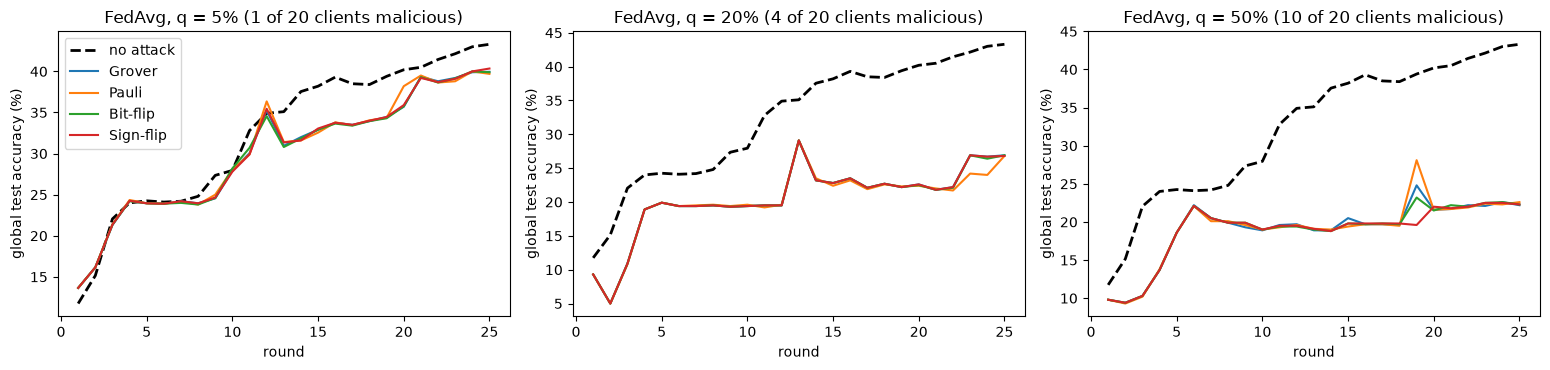

Table 1 analogue, MNIST, accuracy (%) after the last round, no defence:
  q Grover (ours) Grover (paper) Pauli (ours) Pauli (paper) Bit-flip (ours) Bit-flip (paper) Sign-flip (ours) Sign-flip (paper)
 0%  43.3 +/- 3.6          92.65 43.3 +/- 3.6         92.65    43.3 +/- 3.6            92.65     43.3 +/- 3.6             92.65
 5%  40.0 +/- 6.8          40.95 39.7 +/- 6.5         55.59    39.9 +/- 6.8            49.20     40.4 +/- 7.2             72.51
20%          26.9          73.65         26.8         65.51            26.9            78.35             26.8             88.43
50%          22.2          72.94         22.6         67.61            22.3            46.22             22.3             63.38


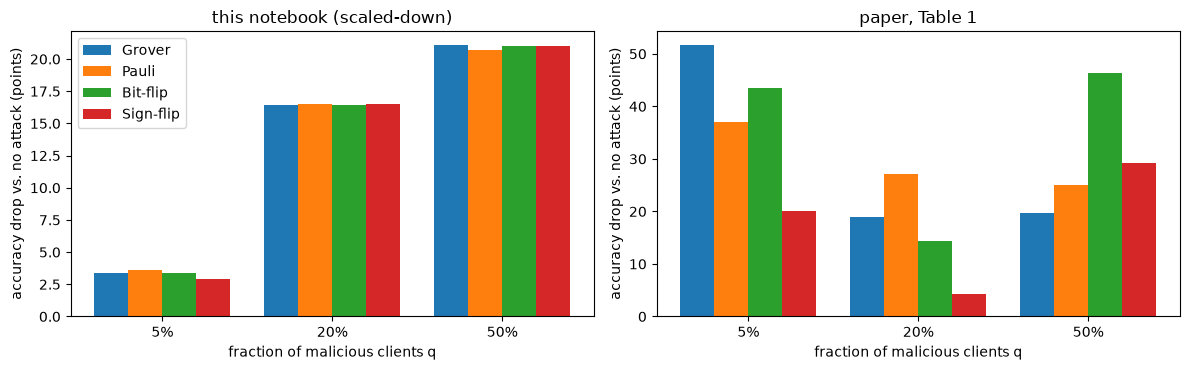

In [12]:
# Paper's Table 1 (MNIST, FedAvg, accuracy %): column 'Pauli' = our 'noise' attack
PAPER_T1 = {  # q (fraction) -> {attack: accuracy}
    0.00: dict(grover=92.65, noise=92.65, bitflip=92.65, signflip=92.65),
    0.05: dict(grover=40.95, noise=55.59, bitflip=49.20, signflip=72.51),
    0.10: dict(grover=74.61, noise=44.48, bitflip=76.06, signflip=73.14),
    0.20: dict(grover=73.65, noise=65.51, bitflip=78.35, signflip=88.43),
    0.30: dict(grover=80.33, noise=57.57, bitflip=71.26, signflip=80.69),
    0.40: dict(grover=71.33, noise=78.21, bitflip=72.86, signflip=73.39),
    0.50: dict(grover=72.94, noise=67.61, bitflip=46.22, signflip=63.38)}

clean_runs = [r for r in resA if r["attack"] is None]
clean_acc = np.mean([r["final"] for r in clean_runs])
print(f"clean FedAvg accuracy of this notebook: {clean_acc:.1f}% (mean of seeds {[r['seed'] for r in clean_runs]}); paper: 92.65%\n")

# accuracy-vs-round curves
qs = sorted(set(r["q"] for r in resA if r["attack"]))
fig, axes = plt.subplots(1, len(qs), figsize=(5.2 * len(qs), 3.8), squeeze=False)
for ax, q in zip(axes[0], qs):
    ax.plot(range(1, ROUNDS + 1), np.mean([r["acc"] for r in clean_runs], 0), "k--", lw=2, label="no attack")
    for atk in ATTACKS:
        rr = [r for r in resA if r["attack"] == atk and r["q"] == q]
        ax.plot(range(1, ROUNDS + 1), np.mean([r["acc"] for r in rr], 0), label=PAPER_NAME[atk])
    ax.set_title(f"FedAvg, q = {q:.0%} ({n_attackers(q)} of {K_CLIENTS} clients malicious)"); ax.set_xlabel("round"); ax.set_ylabel("global test accuracy (%)")
axes[0][0].legend()
plt.tight_layout(); plt.show()

# Table 1 style: ours vs the paper
rows = []
for q in [0.0] + qs:
    row = {"q": f"{q:.0%}"}
    for atk in ATTACKS:
        if q == 0:
            ours = [r["final"] for r in clean_runs]
        else:
            ours = [r["final"] for r in resA if r["attack"] == atk and r["q"] == q]
        sd = f" +/- {np.std(ours):.1f}" if len(ours) > 1 else ""
        row[PAPER_NAME[atk] + " (ours)"] = f"{np.mean(ours):.1f}{sd}"
        row[PAPER_NAME[atk] + " (paper)"] = f"{PAPER_T1[round(q, 2)][atk]:.2f}" if round(q, 2) in PAPER_T1 else "-"
    rows.append(row)
tabA = pd.DataFrame(rows)
print("Table 1 analogue, MNIST, accuracy (%) after the last round, no defence:")
print(tabA.to_string(index=False))

# accuracy drop figure (ours vs the paper), the 'Fig. 3 / Table 1' view
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
w = 0.2
for j, atk in enumerate(ATTACKS):
    ours_drop = [clean_acc - np.mean([r["final"] for r in resA if r["attack"] == atk and r["q"] == q]) for q in qs]
    paper_drop = [92.65 - PAPER_T1[round(q, 2)][atk] if round(q, 2) in PAPER_T1 else np.nan for q in qs]
    ax[0].bar(np.arange(len(qs)) + (j - 1.5) * w, ours_drop, w, label=PAPER_NAME[atk])
    ax[1].bar(np.arange(len(qs)) + (j - 1.5) * w, paper_drop, w, label=PAPER_NAME[atk])
for a, t in zip(ax, ["this notebook (scaled-down)", "paper, Table 1"]):
    a.set_xticks(range(len(qs))); a.set_xticklabels([f"{q:.0%}" for q in qs]); a.axhline(0, color="k", lw=0.6)
    a.set_xlabel("fraction of malicious clients q"); a.set_ylabel("accuracy drop vs. no attack (points)"); a.set_title(t)
ax[0].legend()
plt.tight_layout(); plt.show()

## Experiment B: robust aggregators, and Experiment C: stealth

**B** repeats the attacks with the authors' implementations of Multi-Krum, MUD-HoG (and, in the full run, Krum, FoolsGold and FLGuardian) at one malicious fraction, and measures the accuracy drop relative to each aggregator's *own* clean run, as the paper's heatmaps (Figures 5 and 6) do. **C** (the next cell) checks the stealth claim of Section 6.7: do the malicious updates have norms comparable to honest ones? The ratio of the mean transmitted malicious update norm to the mean honest update norm is plotted for the FedAvg runs of Experiment A.

Experiment B: defences ['mkrum', 'mudhog', 'krum', 'foolsgold', 'flguardian'], attacks ['grover', 'noise', 'bitflip', 'signflip'], q = 20% (4 of 20 malicious), seed 1


quantum/clean/q=0.00/mkrum/seed1               final acc  25.9%  (last-3 mean  25.0%)  [111s]


quantum/grover/q=0.20/mkrum/seed1              final acc  21.5%  (last-3 mean  21.4%)  [162s]


quantum/noise/q=0.20/mkrum/seed1               final acc  22.0%  (last-3 mean  21.7%)  [126s]


quantum/bitflip/q=0.20/mkrum/seed1             final acc  21.4%  (last-3 mean  21.4%)  [120s]


...

quantum/grover/q=0.20/flguardian/seed1         final acc  27.8%  (last-3 mean  26.4%)  [424s]


quantum/noise/q=0.20/flguardian/seed1          final acc  27.3%  (last-3 mean  25.4%)  [276s]


quantum/bitflip/q=0.20/flguardian/seed1        final acc  27.5%  (last-3 mean  26.2%)  [295s]


quantum/signflip/q=0.20/flguardian/seed1       final acc  27.5%  (last-3 mean  26.2%)  [356s]



total compute for experiment B: 76.6 min

Global accuracy (%) after 25 rounds, q = 20%:
            no attack  Grover  Pauli  Bit-flip  Sign-flip
FedAvg           39.7    26.9   26.8      26.9       26.8
MKrum            25.9    21.5   22.0      21.4       21.5
MUD-HoG          37.2    21.5   21.5      21.5       21.5
Krum             22.3    20.9   20.9      20.9       20.9
FoolsGold        40.1    21.3   21.6      21.2       21.2
FLGuardian       39.7    27.8   27.3      27.5       27.5

Accuracy drop vs. the same aggregator's own no-attack run (points; the paper's Fig. 5/6 definition):
            Grover  Pauli  Bit-flip  Sign-flip
FedAvg        12.8   12.9      12.8       12.9
MKrum          4.4    3.9       4.5        4.4
MUD-HoG       15.7   15.7      15.7       15.7
Krum           1.4    1.4       1.4        1.4
FoolsGold     18.8   18.5      18.9       18.9
FLGuardian    11.9   12.4      12.2       12.2


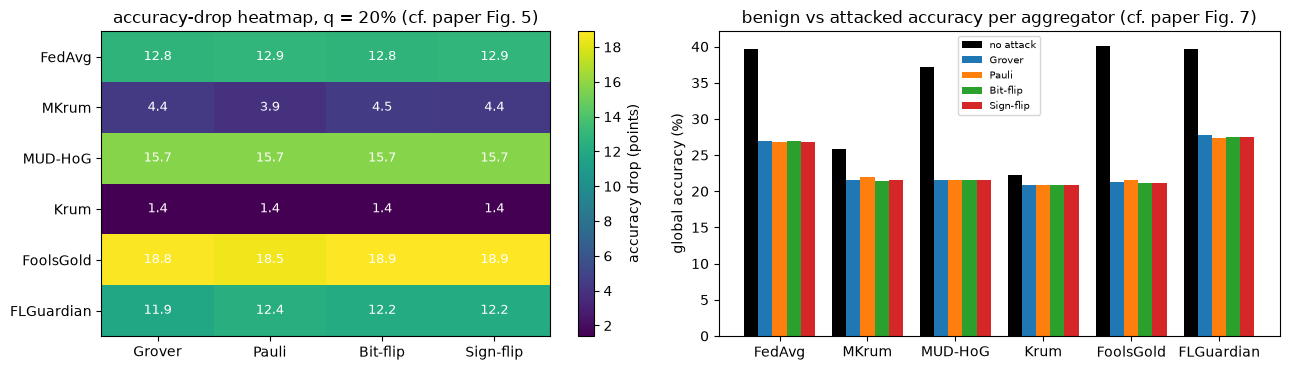

In [13]:
# ---------------- Experiment B: robust aggregators, q = DEF_Q malicious clients ----------------
AGG_NAME = {"fedavg": "FedAvg", "mudhog": "MUD-HoG", "krum": "Krum", "mkrum": "MKrum", "flguardian": "FLGuardian", "foolsgold": "FoolsGold"}
print(f"Experiment B: defences {DEFENSES}, attacks {DEF_ATTACKS}, q = {DEF_Q:.0%} ({n_attackers(DEF_Q)} of {K_CLIENTS} malicious), seed {SEEDS[0]}")
resB = []
for agg in DEFENSES:
    resB.append(show(run_fl(q=0.0, agg=agg, seed=SEEDS[0])))
    for atk in DEF_ATTACKS:
        resB.append(show(run_fl(attack=atk, q=DEF_Q, agg=agg, seed=SEEDS[0])))
dfB = pd.DataFrame([{k: r[k] for k in ("agg", "attack", "q", "final", "last3", "seconds")} for r in resB])
print(f"\ntotal compute for experiment B: {dfB.seconds.sum() / 60:.1f} min")

# FedAvg rows from experiment A at the same q for reference
fedavg_ref = {None: np.mean([r["final"] for r in resA if r["attack"] is None and r["seed"] == SEEDS[0]])}
for atk in DEF_ATTACKS:
    rr = [r for r in resA if r["attack"] == atk and abs(r["q"] - DEF_Q) < 1e-9 and r["seed"] == SEEDS[0]]
    fedavg_ref[atk] = rr[0]["final"] if rr else np.nan

aggs = ["fedavg"] + DEFENSES
acc_tab = pd.DataFrame(index=[AGG_NAME[a] for a in aggs], columns=["no attack"] + [PAPER_NAME[a] for a in DEF_ATTACKS], dtype=float)
drop_tab = acc_tab.copy()
for a in aggs:
    base = fedavg_ref[None] if a == "fedavg" else [r for r in resB if r["agg"] == a and r["attack"] is None][0]["final"]
    acc_tab.loc[AGG_NAME[a], "no attack"] = base
    for atk in DEF_ATTACKS:
        v = fedavg_ref[atk] if a == "fedavg" else [r for r in resB if r["agg"] == a and r["attack"] == atk][0]["final"]
        acc_tab.loc[AGG_NAME[a], PAPER_NAME[atk]] = v
        drop_tab.loc[AGG_NAME[a], PAPER_NAME[atk]] = base - v
drop_tab = drop_tab.drop(columns=["no attack"])
print(f"\nGlobal accuracy (%) after {ROUNDS} rounds, q = {DEF_Q:.0%}:")
print(acc_tab.round(1).to_string())
print("\nAccuracy drop vs. the same aggregator's own no-attack run (points; the paper's Fig. 5/6 definition):")
print(drop_tab.round(1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
im = ax[0].imshow(drop_tab.values.astype(float), cmap="viridis", aspect="auto")
ax[0].set_xticks(range(drop_tab.shape[1])); ax[0].set_xticklabels(drop_tab.columns); ax[0].set_yticks(range(drop_tab.shape[0])); ax[0].set_yticklabels(drop_tab.index)
for i in range(drop_tab.shape[0]):
    for j in range(drop_tab.shape[1]):
        ax[0].text(j, i, f"{drop_tab.values[i, j]:.1f}", ha="center", va="center", color="w", fontsize=9)
plt.colorbar(im, ax=ax[0], label="accuracy drop (points)"); ax[0].set_title(f"accuracy-drop heatmap, q = {DEF_Q:.0%} (cf. paper Fig. 5)")
xx = np.arange(len(aggs)); w = 0.8 / (1 + len(DEF_ATTACKS))
ax[1].bar(xx - 0.4 + w / 2, acc_tab["no attack"], w, color="k", label="no attack")
for j, atk in enumerate(DEF_ATTACKS):
    ax[1].bar(xx - 0.4 + w * (j + 1.5), acc_tab[PAPER_NAME[atk]], w, label=PAPER_NAME[atk])
ax[1].set_xticks(xx); ax[1].set_xticklabels([AGG_NAME[a] for a in aggs]); ax[1].set_ylabel("global accuracy (%)"); ax[1].set_title("benign vs attacked accuracy per aggregator (cf. paper Fig. 7)")
ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

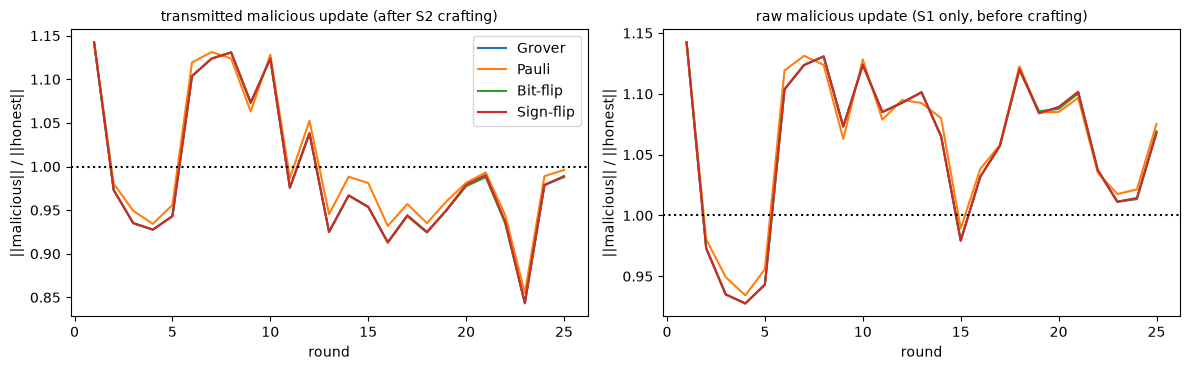

Norm ratio malicious/honest, FedAvg, q = 20% (1.0 = indistinguishable by norm):
   attack  mean ratio raw update  mean ratio transmitted update  min ratio transmitted  max ratio transmitted
   Grover                   1.06                           0.99                   0.84                   1.14
    Pauli                   1.06                           1.00                   0.86                   1.14
 Bit-flip                   1.06                           0.99                   0.84                   1.14
Sign-flip                   1.06                           0.99                   0.84                   1.14

Note: the authors' crafting step (S2) only starts after the attacker has 10 rounds of history, i.e. from round 11 on; this run has 25 rounds, so S2 is active in the last 15 rounds.


In [14]:
# ---------------- Stealth: do the malicious updates look like honest ones? (paper Sec. 6.7) ----------------
# norm ratio = mean L2 norm of the transmitted malicious update / mean L2 norm of honest updates, per round, FedAvg runs
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
stealth_rows = []
for atk in ATTACKS:
    rr = [r for r in resA if r["attack"] == atk and abs(r["q"] - DEF_Q) < 1e-9 and r["seed"] == SEEDS[0]]
    if not rr:
        continue
    r = rr[0]
    sent = np.array(r["mal_sent_norm"]) / np.array(r["benign_norm"])
    raw = np.array(r["mal_raw_norm"]) / np.array(r["benign_norm"])
    ax[0].plot(range(1, len(sent) + 1), sent, label=PAPER_NAME[atk])
    ax[1].plot(range(1, len(raw) + 1), raw, label=PAPER_NAME[atk])
    stealth_rows.append({"attack": PAPER_NAME[atk], "mean ratio raw update": raw.mean(), "mean ratio transmitted update": sent.mean(),
                         "min ratio transmitted": sent.min(), "max ratio transmitted": sent.max()})
for a, t in zip(ax, ["transmitted malicious update (after S2 crafting)", "raw malicious update (S1 only, before crafting)"]):
    a.axhline(1.0, color="k", ls=":"); a.set_xlabel("round"); a.set_ylabel("||malicious|| / ||honest||"); a.set_title(t, fontsize=10)
ax[0].legend(); plt.tight_layout(); plt.show()
tabS = pd.DataFrame(stealth_rows)
print(f"Norm ratio malicious/honest, FedAvg, q = {DEF_Q:.0%} (1.0 = indistinguishable by norm):")
print(tabS.round(2).to_string(index=False))
print(f"\nNote: the authors' crafting step (S2) only starts after the attacker has 10 rounds of history, i.e. from round 11 on; "
      f"this run has {ROUNDS} rounds, so {'S2 is active in the last ' + str(max(0, ROUNDS - 10)) + ' rounds' if ROUNDS > 10 else 'S2 was never active'}.")

## Classical baseline and the learned angles

The paper compares only against defences, not against a classical model. As the required classical baseline we train, with the identical federation, split, optimiser and budget (clean, FedAvg), (i) a *classical twin* of the hybrid network in which the quantum layer is replaced by a 4-to-4 linear layer with tanh, and (ii) the authors' classical LeNet (`tasks.mnist.Net`). Then we look at the four-dimensional angle vector that the CNN front-end of the trained hybrid model feeds into the circuit.

classical_twin/clean/q=0.00/fedavg/seed1       final acc  48.6%  (last-3 mean  48.2%)  [88s]


lenet/clean/q=0.00/fedavg/seed1                final acc  93.6%  (last-3 mean  93.6%)  [109s]


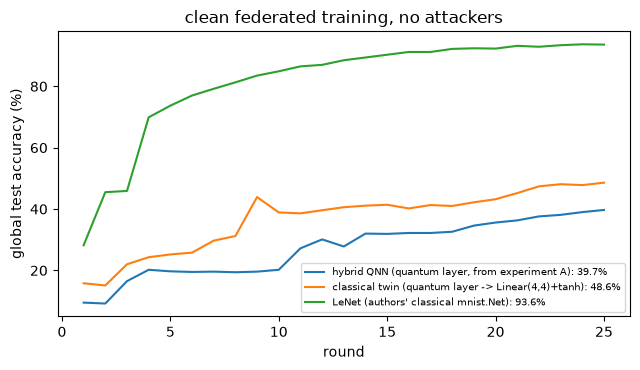

The circuit-level attacks of the paper exist only for the quantum layer, so the classical models are clean-training references only.
They show how much of the (low) absolute accuracy is due to the tiny budget rather than to the quantum layer.


In [15]:
# ---------------- Classical federated baselines on exactly the same data, split and budget (clean, FedAvg) ----------------
base = {"hybrid QNN (quantum layer, from experiment A)": clean_runs[0],
        "classical twin (quantum layer -> Linear(4,4)+tanh)": show(run_fl(model="classical_twin", q=0.0, agg="fedavg", seed=SEEDS[0])),
        "LeNet (authors' classical mnist.Net)": show(run_fl(model="lenet", q=0.0, agg="fedavg", seed=SEEDS[0]))}
plt.figure(figsize=(6.5, 3.8))
for name, r in base.items():
    plt.plot(range(1, r["rounds"] + 1), r["acc"], label=f"{name}: {r['final']:.1f}%")
plt.xlabel("round"); plt.ylabel("global test accuracy (%)"); plt.title("clean federated training, no attackers"); plt.legend(fontsize=7)
plt.tight_layout(); plt.show()
print("The circuit-level attacks of the paper exist only for the quantum layer, so the classical models are clean-training references only.")
print("They show how much of the (low) absolute accuracy is due to the tiny budget rather than to the quantum layer.")

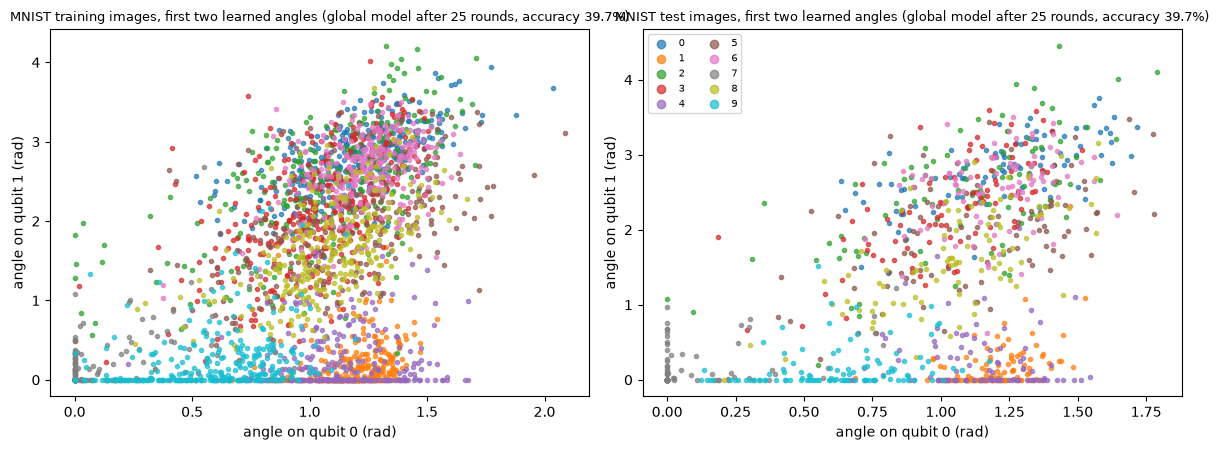

   trojan  P(payload runs), uniform angles  P(payload runs), learned angles  mean |z_trojan - cos(x)|  mean |z_trojan - z_clean|
   Grover                            0.063                            0.000                     0.054                      0.684
    Pauli                            0.065                            0.073                     0.059                      0.667
 Bit-flip                            0.063                            0.000                     0.060                      0.620
Sign-flip                            0.063                            0.000                     0.069                      0.655

When the flag does not fire the trojan layer returns about cos(x): the trainable ansatz is bypassed. In a poisoned round the client therefore trains its CNN against (almost) no quantum layer, whatever the 'attack' is called; this is why the four attacks behave alike in the runs above.


In [16]:
# ---------------- Angles actually learned by the CNN front-end (the data the circuit receives) ----------------
r0 = clean_runs[0]
fq = FastQNet()
fq.load_state_dict(torch.load(DATA_DIR / "results" / (r0["key"] + ".pt")))
fq.eval()
fed = get_federation("mnist", r0["seed"])
cmap = plt.get_cmap("tab10")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for a, (ds, nm) in zip(ax, [(fed["train_ds"], "training"), (fed["test_ds"], "test")]):
    with torch.no_grad():
        h = F.max_pool2d(F.relu(fq.conv1(ds.X)), 2); h = F.max_pool2d(F.relu(fq.conv2(h)), 2)
        ang = F.relu(fq.fc1(h.view(len(ds), -1))).numpy()
    for c in range(10):
        m = ds.targets.numpy() == c
        a.scatter(ang[m, 0], ang[m, 1], s=9, color=cmap(c), label=str(c), alpha=0.7)
    a.set_xlabel("angle on qubit 0 (rad)"); a.set_ylabel("angle on qubit 1 (rad)")
    a.set_title(f"MNIST {nm} images, first two learned angles (global model after {r0['rounds']} rounds, accuracy {r0['final']:.1f}%)", fontsize=9)
ax[1].legend(ncol=2, fontsize=7, markerscale=2)
plt.tight_layout(); plt.show()

# ---------------- How often does the trojan payload actually run? ----------------
# The flag (multi-controlled X) fires only when the data register is measured as the marked bit-string, so the payload
# (Grover diffusion / rotations / QFT, and crucially the trainable ansatz) acts with probability P(marked).
# P(marked) = prod_i p_i with p_i = sin^2(x_i/2) for a marked bit 1 and cos^2(x_i/2) for a marked bit 0 (RX and RY embeddings agree).
with torch.no_grad():
    h = F.max_pool2d(F.relu(fq.conv1(fed["test_ds"].X)), 2); h = F.max_pool2d(F.relu(fq.conv2(h)), 2)
    ang_learned = F.relu(fq.fc1(h.view(len(fed["test_ds"]), -1)))
ang_uniform = torch.rand(2000, N_QUBITS) * math.pi
def p_fire(x, marked):
    m = torch.tensor(marked, dtype=torch.float32)
    return torch.where(m == 1, torch.sin(x / 2) ** 2, torch.cos(x / 2) ** 2).prod(1)
rows = []
for name, marked, kw in [("grover", [1, 0, 1, 0], dict(marked_state=[1, 0, 1, 0])), ("noise", [0, 1, 0, 1], dict(trigger_angles=ANGLES)),
                         ("bitflip", [1, 0, 1, 0], dict(period=3, marked_state=[1, 0, 1, 0])), ("signflip", [1, 0, 1, 0], dict(phase=0.25, marked_state=[1, 0, 1, 0]))]:
    lay = FastQLayer(N_QUBITS, Q_DEPTH, name, **kw); clean = FastQLayer(N_QUBITS, Q_DEPTH, "clean")
    with torch.no_grad():
        clean.weights.copy_(lay.weights)
        emb = torch.cos(ang_uniform)                                   # output if no gate after the embedding acted
        rows.append({"trojan": PAPER_NAME[name], "P(payload runs), uniform angles": p_fire(ang_uniform, marked).mean().item(),
                     "P(payload runs), learned angles": p_fire(ang_learned, marked).mean().item(),
                     "mean |z_trojan - cos(x)|": (lay(ang_uniform) - emb).abs().mean().item(),
                     "mean |z_trojan - z_clean|": (lay(ang_uniform) - clean(ang_uniform)).abs().mean().item()})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\nWhen the flag does not fire the trojan layer returns about cos(x): the trainable ansatz is bypassed. In a poisoned round the client therefore trains "
      "its CNN against (almost) no quantum layer, whatever the 'attack' is called; this is why the four attacks behave alike in the runs above.")

## CIFAR-10 and PennyLane end-to-end smoke tests

Two things are checked here, neither of which can reproduce the paper's accuracies.

1. **The authors' own PennyLane model, end to end.** The federated runs above use the exact `FastQLayer`; this cell runs the authors' unchanged `tasks.mnist.QNet` (real PennyLane QNodes, clean and trojan) through the same federation code for a tiny federation, to show that the stand-in is only a speed-up.
2. **CIFAR-10 with the authors' unchanged `tasks.cifar.QNet`** (a 4-million-parameter CNN front-end plus the 8+1 qubit PennyLane circuit). One CIFAR round at full size costs minutes of CPU time, so the federation is tiny (a few clients, a few hundred images, a few rounds): accuracy stays near the 10 % chance level and **no CIFAR-10 claim of the paper can be checked**. We also inspect the CIFAR trojan circuits of the repository, because only the Grover one turned out to be usable (see the output).

In [17]:
import inspect
# ---- (1) authors' PennyLane QNet end to end (tiny federation) ----
pl_clean = show(run_fl(model="pennylane", q=0.0, agg="fedavg", seed=1, rounds=1, k=4, n_train=96, n_test=100, tag="_plsmoke"))
pl_atk = show(run_fl(model="pennylane", attack="grover", q=0.25, agg="fedavg", seed=1, rounds=1, k=4, n_train=96, n_test=100, tag="_plsmoke"))
print("-> the authors' PennyLane QNet trains inside the same federation (clean and with one Grover attacker).\n")

# ---- (2) CIFAR-10 circuits of the repository: which trojans actually do something? ----
cm = R_cifar.QNet()
xin = torch.rand(4, 8) * np.pi
print("CIFAR-10 trojan factories of the authors' tasks/cifar.py (same dispatch rule as Attacker_QuantumTrojan):")
for name in ["grover", "noise", "bitflip", "signflip"]:
    fac = getattr(cm, f"q_layer_{name}")
    args = TRIG[name]
    try:
        layer = fac(args) if len(inspect.signature(fac).parameters) == 1 else fac(*args)
        with torch.no_grad():
            layer.weights.copy_(cm.q_layer.weights)
            d = (layer(xin) - cm.q_layer(xin)).abs().max().item()
        print(f"  {name:9s}: builds; max |trojan output - clean output| with identical weights = {d:.2e}"
              + ("   <- payload never fires, circuit equals the clean one" if d < 1e-6 else ""))
    except Exception as e:
        print(f"  {name:9s}: cannot even be built -> {type(e).__name__}: {str(e)[:90]}")
del cm

# ---- (3) CIFAR-10 federated smoke run (unchanged authors' CIFAR QNet) ----
CIFAR_Q = 0.25 if CIFAR_K == 4 else 0.34
kw = dict(task="cifar", model="quantum", seed=1, rounds=CIFAR_ROUNDS, k=CIFAR_K, n_train=CIFAR_N, n_test=100, lr=0.001, save_model=False, tag="_smoke")
print(f"\nCIFAR-10 smoke test: {CIFAR_K} clients, {CIFAR_N} training images, {CIFAR_ROUNDS} round(s), lr 1e-3")
cf_clean = show(run_fl(q=0.0, agg="fedavg", **kw))
cf_atk = show(run_fl(attack="grover", q=CIFAR_Q, agg="fedavg", **kw))
print("\nCIFAR-10 accuracies here are at (or near) chance level: they illustrate that the pipeline runs, nothing more.")

pennylane/clean/q=0.00/fedavg/seed1            final acc  14.0%  (last-3 mean  14.0%)  [1s]


pennylane/grover/q=0.25/fedavg/seed1           final acc  10.0%  (last-3 mean  10.0%)  [1s]


-> the authors' PennyLane QNet trains inside the same federation (clean and with one Grover attacker).

CIFAR-10 trojan factories of the authors' tasks/cifar.py (same dispatch rule as Attacker_QuantumTrojan):


  grover   : builds; max |trojan output - clean output| with identical weights = 1.09e+00


  noise    : builds; max |trojan output - clean output| with identical weights = 1.09e+00
  bitflip  : cannot even be built -> TypeError: qnode_bitflip() missing 1 required positional argument: 'marked_state'
  signflip : cannot even be built -> TypeError: qnode_signflip() missing 1 required positional argument: 'marked_state'

CIFAR-10 smoke test: 6 clients, 192 training images, 3 round(s), lr 1e-3


quantum/clean/q=0.00/fedavg/seed1              final acc   5.0%  (last-3 mean   5.0%)  [49s]


quantum/grover/q=0.33/fedavg/seed1             final acc   8.0%  (last-3 mean   6.3%)  [53s]



CIFAR-10 accuracies here are at (or near) chance level: they illustrate that the pipeline runs, nothing more.


## Side-by-side comparison with the paper

Verdict rule: a number is **reproduced** when it is within 2 accuracy points of the paper, otherwise **not reached** (below) or **exceeded** (above) with the gap; rows marked *direction* test the qualitative statement of the paper; **cannot be checked** means this notebook did not run the needed experiment. Please read the scale warning at the top: with about 3 % of the paper's training budget, absolute accuracies are expected to be "not reached".

In [18]:
# ---------------- Paper vs this notebook, one verdict per checkable claim ----------------
TOL = 2.0   # accuracy points ("reproduced" = within 2 points of the paper)
def verdict(paper, ours, tol=TOL):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)):
        return "cannot be checked"
    d = ours - paper
    if abs(d) <= tol:
        return "reproduced"
    return f"exceeded (+{d:.1f})" if d > 0 else f"not reached ({d:.1f})"

rows = []
def add(claim, paper, ours, verdict_text):
    f = lambda v: "-" if v is None else (f"{v:.2f}" if isinstance(v, (int, float, np.floating)) else str(v))
    rows.append({"claim": claim, "paper": f(paper), "this notebook": f(ours), "verdict": verdict_text})

acc_of = lambda attack, q, agg="fedavg": (np.mean([r["final"] for r in resA if r["attack"] == attack and abs(r["q"] - q) < 1e-9])
                                          if any(r["attack"] == attack and abs(r["q"] - q) < 1e-9 for r in resA) else None)
# C1 clean accuracy
add("MNIST clean QFL accuracy, FedAvg (Table 1)", 92.65, clean_acc, verdict(92.65, clean_acc))
# C2 Table-1 numbers and direction for every q we ran
for q in qs:
    for atk in ATTACKS:
        ours = acc_of(atk, q)
        pv = PAPER_T1.get(round(q, 2), {}).get(atk)
        add(f"MNIST {PAPER_NAME[atk]} attack, q = {q:.0%}, accuracy (Table 1)", pv, ours, verdict(pv, ours) if pv is not None else "cannot be checked")
    drops = [clean_acc - acc_of(atk, q) for atk in ATTACKS]
    pdrops = [92.65 - PAPER_T1[round(q, 2)][atk] for atk in ATTACKS] if round(q, 2) in PAPER_T1 else [np.nan]
    ok = sum(d >= 5 for d in drops)
    add(f"direction: q = {q:.0%} malicious clients lower accuracy by >= 5 points (attacks satisfying it)", f"{sum(d >= 5 for d in pdrops)}/4 attacks (mean drop {np.mean(pdrops):.1f})",
        f"{ok}/4 attacks (mean drop {np.mean(drops):.1f})", "reproduced (direction)" if ok == 4 else ("partly reproduced" if ok > 0 else "not reached"))
if 0.05 in qs:
    m5 = np.mean([acc_of(a, 0.05) for a in ATTACKS])
    add("MNIST mean accuracy over the 4 attacks with a single attacker (q = 5 %)", 54.56, m5, verdict(54.56, m5))
else:
    add("MNIST mean accuracy over the 4 attacks with a single attacker (q = 5 %)", 54.56, None, "cannot be checked (q = 5 % not run in FAST_MODE)")
# C3 non-monotonic in q
if len(qs) >= 3:
    nonmono = [PAPER_NAME[a] for a in ATTACKS if any(acc_of(a, qs[j + 1]) > acc_of(a, qs[j]) + 1e-9 for j in range(len(qs) - 1))]
    add("accuracy is not monotone in q (some attack recovers at higher q)", "yes, all 4 attacks", f"{len(nonmono)}/4 attacks ({', '.join(nonmono) or 'none'})",
        "reproduced (direction)" if len(nonmono) >= 1 else "not reached")
else:
    add("accuracy is not monotone in q (some attack recovers at higher q)", "yes, all 4 attacks", None, "cannot be checked (needs >= 3 values of q; FAST_MODE runs one)")
# C4 clean cost of robust aggregators (paper: absolute clean accuracy per aggregator, MNIST)
PAPER_CLEAN = {"mudhog": 91.79, "krum": 48.13, "mkrum": 85.00, "flguardian": 76.53, "foolsgold": 89.15}
for a in DEFENSES:
    ours = [r for r in resB if r["agg"] == a and r["attack"] is None][0]["final"]
    add(f"{AGG_NAME[a]} clean accuracy cost relative to FedAvg (points)", PAPER_CLEAN[a] - 92.65, ours - clean_acc, verdict(PAPER_CLEAN[a] - 92.65, ours - clean_acc))
if "krum" in DEFENSES and "mudhog" in DEFENSES:
    kr = [r for r in resB if r["agg"] == "krum" and r["attack"] is None][0]["final"]; mh = [r for r in resB if r["agg"] == "mudhog" and r["attack"] is None][0]["final"]
    add("Krum much worse than MUD-HoG without any attacker (gap > 10 points)", f"gap {91.79 - 48.13:.1f}", f"gap {mh - kr:.1f}", "reproduced (direction)" if mh - kr > 10 else "not reached")
# C5 defences leave worst-case failures
dmax = float(np.nanmax(drop_tab.drop(index="FedAvg").values.astype(float)))
add("worst-case accuracy drop that survives a robust aggregator (points; abstract: 'up to 50%')", 50.0, dmax, verdict(50.0, dmax))
add("direction: some robust aggregator loses >= 10 points under some attack", "yes", f"max drop {dmax:.1f}", "reproduced (direction)" if dmax >= 10 else "not reached")
# C6 MKrum at 20% (paper Sec. 6.5)
PAPER_MK20 = {"grover": 83.07, "noise": 75.59, "bitflip": 79.59, "signflip": 63.95}
if "mkrum" in DEFENSES and abs(DEF_Q - 0.2) < 1e-9:
    for atk in DEF_ATTACKS:
        ours = [r for r in resB if r["agg"] == "mkrum" and r["attack"] == atk][0]["final"]
        add(f"MKrum, {PAPER_NAME[atk]} attack, q = 20 % (accuracy)", PAPER_MK20[atk], ours, verdict(PAPER_MK20[atk], ours))
# C7 stealth
st_ok = []
for atk in ATTACKS:
    rr = [r for r in resA if r["attack"] == atk and abs(r["q"] - DEF_Q) < 1e-9 and r["seed"] == SEEDS[0]]
    if rr:
        sent = np.array(rr[0]["mal_sent_norm"]) / np.array(rr[0]["benign_norm"])
        st_ok.append(float(np.mean(sent[10:] if len(sent) > 10 else sent)))
if st_ok:
    inside = sum(0.5 <= v <= 2.0 for v in st_ok)
    add("malicious updates stay within a factor 2 of the honest update norm (Sec. 6.7; rounds with S2 active)", "norm-matched ('close to benign norms')",
        f"ratios {[round(v, 2) for v in st_ok]}", "reproduced (direction)" if inside == len(st_ok) else ("partly reproduced" if inside else "not reached"))
# C8 not checkable here
add("CIFAR-10: clean 70.15 %; q = 5 % -> Grover 34.87, Pauli 47.10, Bit-flip 44.01, Sign-flip 58.77", "see Table 1", f"smoke test only: {cf_clean['final']:.0f}% clean, {cf_atk['final']:.0f}% with Grover", "cannot be checked")
add("poisoning-ratio sweep (Fig. 2) and the choice rho = 0.9", "Fig. 2", None, "cannot be checked (not re-run)")
add("Lemma 1 / Proposition 1 / Theorem 1 (bounded drift, sufficient condition)", "proofs", None, "cannot be checked (theoretical)")
tab_cmp = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 220)
print(tab_cmp.to_string(index=False))
print("\nverdict counts:", tab_cmp.verdict.str.split(" ").str[0].value_counts().to_dict())

                                                                                               claim                                  paper                             this notebook                         verdict
                                                          MNIST clean QFL accuracy, FedAvg (Table 1)                                  92.65                                     43.30             not reached (-49.4)
                                                     MNIST Grover attack, q = 5%, accuracy (Table 1)                                  40.95                                     39.95                      reproduced
                                                      MNIST Pauli attack, q = 5%, accuracy (Table 1)                                  55.59                                     39.70             not reached (-15.9)
                                                   MNIST Bit-flip attack, q = 5%, accuracy (Table 1)                                  49.20     

## Reading the paper critically

Observations from reading the authors' code at the pinned commit and from the runs above (they concern the *evidence*, not the sincerity of the work).

1. **"Backdoor" means accuracy loss here.** The paper measures an attack by the drop of overall test accuracy. There is no target label and no triggered test set in the evaluation; the repository's `Server.test_backdoor_quantum` is marked `# TODO: Doesn't work currently`. The attacks therefore behave like *untargeted* model poisoning, and the claim "backdoor" is about the mechanism (a swapped circuit), not about a trigger that flips predictions on demand.
2. **What the poisoned round really does.** In the code a malicious client builds a *new* trojan layer every round with fresh random circuit weights (`qml.qnn.TorchLayer` initialises its own parameters) and trains the shared CNN/head through that unrelated circuit with a doubled loss; the trojan weights are then discarded and only the shared classical weights are sent. The harm comes from mismatching the classical layers with a different circuit, which is a weaker and less "quantum" statement than the paper's Sections 4.1-4.2 suggest. The equivalence table above shows the four trojan circuits do produce different outputs from the clean one, so the mismatch is real. Moreover the payload (and with it the trainable ansatz) only acts on the branch where the multi-controlled flag fires, i.e. for a small fraction of inputs (see the payload-firing table next to the learned-angle plot); on all other inputs a trojan layer returns roughly the bare embedding `cos(x)`. In practice the four "different" attacks therefore replace the quantum layer by nearly the same function, and differences between them in a single-seed table such as Table 1 are expected to be mostly noise.
3. **Update crafting (S2) is delayed and unusual.** The crafted update only starts after the attacker has 10 stored updates, and the stored "honest-like" history consists of the attacker's *own* raw (poisoned) updates. The intensity floor is 10 (`min_eps = 10`) and the result is rescaled to the history's mean norm, so the transmitted norm is benign-like by construction (our norm-ratio plot) - the stealth is a property of the rescaling, not something discovered by the experiments. Because aggregators call `getDelta()` repeatedly and the attacker re-draws its poisoning decision and noise on every call, the attacker is not a fixed adversary in the way the threat model implies.
4. **Non-monotone curves and one seed.** The paper explains the non-monotone accuracy-versus-q curves by non-IID splits and aggregator selection effects. With 5 seeds averaged, no confidence intervals are given; in our single-seed runs the round-to-round noise of the global accuracy is several points, enough to produce the same pattern without any special mechanism. The authors' Dirichlet partitioner also re-seeds NumPy with 1 internally, so "5 seeds" varies initialisation and batch order but not the client partition.
5. **Scale and budget.** The paper's clean MNIST accuracy (92.65 %) needs the full training set and 100 rounds; our budget is about 3 % of that, so accuracy levels cannot be compared and a q = 5 % attacker in a 20-client federation barely moves a still-untrained model. The notebook can only test direction and ordering. The repository README uses 10 clients by default while the paper states 20.
6. **Defences.** Krum with the repository's default `f` selects a single client out of 20 non-IID clients, which explains its poor clean accuracy; calling this "robust aggregation costs accuracy" conflates a design choice with a defence-specific cost. MUD-HoG is run with the DBSCAN parameters of the original MNIST setup; none of the defences was re-tuned for quantum updates.
7. **CIFAR-10 code path.** In `tasks/cifar.py` the Pauli, Bit-flip and Sign-flip trojans put the multi-controlled X on the data wires instead of the ancilla, so their payload (controlled on the ancilla) never runs, and the Bit-flip and Sign-flip factories take one argument while their circuits need two (they raise an error as soon as a malicious client is built). Only the Grover trojan is functional for CIFAR-10 in the released code (see the smoke-test output), which makes the CIFAR-10 half of Table 1 hard to reproduce from the repository.
8. **Theory.** Theorem 1 only says that if a drift is larger than the margin of a fraction of test points, those points may flip; it does not use any quantum property and does not bound the drift achieved by the attacks.

## Exercises

1. Set `FAST_MODE = False` and add the q values 10, 30 and 40 % to `Q_GRID`. Does the non-monotone pattern persist when two further seeds are averaged? Report the standard deviation per cell.
2. Raise `ROUNDS` to 60 and lower `LR` to 1e-2. How does the clean accuracy of the classical twin and of the hybrid QNN change, and does the gap in the "direction" rows of the verdict table grow?
3. Change `TRIG["grover"]` to a different marked state, or replace the `FastQLayer` trojan weights by the *clean* layer's weights (a trojan that shares the honest circuit parameters). Which of the four attacks still degrade FedAvg?
4. Implement the attack-specific defence that the paper suggests in its conclusion: a server-side check that compares a client's expectation values `z(x; theta)` on a small public batch with the global model's. Does it detect the attackers when the norms look benign?
5. Make the paper's CIFAR-10 attacks work: fix the multi-controlled X target and the factory signatures in a copy of `tasks/cifar.py`, then repeat the circuit-equivalence check of this notebook for 9 wires and compare the clean and trojan outputs.